In [1]:
!unzip -q -o /content/TPI_HbA1c_reinternacion.zip -d /content
%cd /content/TPI_HbA1c_reinternacion/notebooks
!pip install -q -r ../requirements.txt

/content/TPI_HbA1c_reinternacion/notebooks


# TP Integrador — Decision Intelligence Capstone

**Cátedra:** Estadística Aplicada y Modelos de Regresión (EAyMR 2026) — UCA, Facultad de Ingeniería y Ciencias Agrarias
**Dataset:** *Diabetes 130-US Hospitals for Years 1999–2008* — UCI Machine Learning Repository (id 296)

| Rol Scrum | Integrante | Responsabilidad principal en este notebook |
|---|---|---|
| Project Lead & Scrum Master | _completar_ | Marco estratégico (§1), contratos de datos (`src/tpi/config.py`), integración |
| Backend & ML / Causal Engineer | _completar_ | Fases 1–4 (`src/tpi/stats.py`, `models.py`, `causal.py`) |
| Frontend & UI/UX Engineer | _completar_ | App Streamlit (`app/app.py`), visualizaciones |
| QA & Validation Engineer | _completar_ | `tests/` (pytest), `ruff`, veredicto del Quality Gate |

## Resumen ejecutivo

**Problema.** Un hospital quiere reducir las **reinternaciones a 30 días** de pacientes diabéticos, que son caras y (en EE.UU.) penalizadas. La palanca candidata es una **política clínica**: medir la hemoglobina glicosilada (HbA1c) durante la internación, que hoy se pide sólo a ~18% de los pacientes.

**Dos preguntas, dos herramientas.**
1. *Predicción* $P(Y \mid X)$: ¿quién se va a reinternar? → torneo de modelos (Fase 3).
2. *Intervención* $P(Y \mid do(T))$: si **obligamos** a medir HbA1c, ¿cuántas reinternaciones evitamos? → inferencia causal (Fase 4).

**Hallazgos principales** (se desarrollan y verifican en cada sección):

* La comparación directa sugiere que medir HbA1c reduce la reinternación **0,71 pp** (p ≈ 0,01). Es **sesgo de autoselección**: el test se pide más a pacientes jóvenes y con menos internaciones previas.
* Ajustando por los confusores medidos **al ingreso** (criterio backdoor verificado formalmente sobre el DAG), el efecto promedio cae a **≈ −0,2 pp** y **no es distinguible de cero** con regresión, IPW y Double ML.
* **Corrección metodológica clave respecto de un análisis previo:** los *días de internación* son posteriores al test (descendiente de $T$); incluirlos como "confusor" duplica artificialmente el efecto (−0,43 pp). Lo mismo ocurre con el mediador y el colisionador.
* El efecto es **heterogéneo**: el beneficio se concentra en pacientes **con internaciones previas** y desaparece en **diagnóstico circulatorio**. Una política **focalizada** (11% de los pacientes) evita ≈ 11 veces más reinternaciones por cada 100 tests que medir a todos.
* Predictivamente la reinternación es **difícil** (AUC test ≈ 0,62). La variable más predictiva (internaciones previas) **no es una palanca**: no se puede intervenir el pasado.

## 0. Configuración y reproducibilidad

Todo el código reutilizable vive en `src/tpi/` (testeado con `pytest`); el notebook orquesta y narra. La semilla global es `SEED = 42` y $\alpha = 0{,}05$ se fija **a priori** para todos los contrastes.

In [2]:
# En Google Colab: clonar el repo y descomentar
# !pip install -q -r requirements.txt
import sys
import warnings
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "tpi").exists())
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from IPython.display import display
from scipy import stats

from tpi import causal as C
from tpi import models as Mdl
from tpi import stats as S
from tpi.config import ALPHA, N_FOLDS, PCA_VARS, PRED_NUM, SEED, Z_CAT, Z_NUM
from tpi.data import auditoria_centinelas, build_features, clean, load_raw

np.random.seed(SEED)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold"})
FIG = iter(range(1, 100))  # numeración de figuras
print(f"Python {sys.version.split()[0]} | numpy {np.__version__} | pandas {pd.__version__} | "
      f"scikit-learn {sklearn.__version__} | SEED={SEED} | α={ALPHA}")

Python 3.13.18 | numpy 2.5.3 | pandas 3.0.5 | scikit-learn 1.9.1 | SEED=42 | α=0.05


# 1. Diagnóstico del problema y objetivos

## 1.1 Contexto operativo

Cada reinternación precoz implica una cama ocupada, costos no reembolsados y, en EE.UU., penalizaciones del programa de reducción de reinternaciones. En pacientes diabéticos internados por **otra** causa (cardíaca, respiratoria, quirúrgica), el control glucémico suele quedar en segundo plano. Strack et al. (2014), autores del dataset, plantearon exactamente la pregunta de si **medir HbA1c** (marcador de atención a la diabetes) se asocia con menos reinternaciones.

**Restricciones reales del sistema:** el laboratorio y el tiempo médico para ajustar tratamientos son limitados; la decisión de medir no es aleatoria (depende de la especialidad, el motivo de ingreso y el criterio médico); los datos son registros administrativos con códigos faltantes y centinelas.

## 1.2 Preguntas e hipótesis

| # | Pregunta | Tipo | Sección |
|---|---|---|---|
| P1 | ¿Difiere la tasa de reinternación entre pacientes con y sin HbA1c medida? | Asociación | §4.1 |
| P2 | ¿Los reinternados tuvieron internaciones índice más largas? | Asociación | §4.2 |
| P3 *(adicional)* | ¿El uso previo del hospital (internaciones del último año) marca a los reinternados? | Asociación | §4.3 |
| P4 | ¿Varía la polifarmacia (nº de medicamentos) entre grupos etarios? | ANOVA | §5 |
| P5 | ¿Qué determina la duración de la internación (recurso cama)? | Regresión MCO | §6 |
| P6 | ¿Quién se va a reinternar? | Predicción | §8–9 |
| P7 | ¿Cuál es el efecto causal **promedio y por subgrupo** de medir HbA1c sobre la reinternación? | Causal | §10–11 |
| P8 *(adicional)* | ¿A qué pacientes conviene priorizar si el recurso es limitado? | Decisión | §12 |

# 2. Datos: auditoría forense (DGP) y limpieza

## 2.1 Carga y códigos centinela

El archivo codifica los faltantes como `"?"`, pero además hay **centinelas numéricos**: códigos válidos en apariencia que significan "no disponible" (verificados contra `IDs_mapping.csv`, que acompaña al dataset). Un modelo que los trate como categorías "reales" aprendería artefactos de carga de datos. Ojo también con el texto `"None"` en `A1Cresult`: **no** es un faltante, significa "el test no se realizó" y define nuestro tratamiento.

In [3]:
raw = load_raw()
print(f"Base original: {raw.shape[0]:,} internaciones × {raw.shape[1]} columnas")
display(auditoria_centinelas(raw))
falt = (raw.isna().mean() * 100).loc[lambda s: s > 0].sort_values(ascending=False).rename("% faltante ('?')")
display(falt.to_frame())

Base original: 101,766 internaciones × 50 columnas


,variable,codigo,significado,n,%
0,admission_type_id,5,Not Available,4785,4.7020
1,admission_type_id,6,NULL,5291,5.1992
2,admission_type_id,8,Not Mapped,320,0.3144
3,admission_source_id,9,Not Available,125,0.1228
4,admission_source_id,15,Not Available,0,0.0000
5,admission_source_id,17,NULL,6781,6.6633
6,admission_source_id,20,Not Mapped,161,0.1582
7,admission_source_id,21,Unknown/Invalid,0,0.0000
8,discharge_disposition_id,18,NULL,3691,3.6269
9,discharge_disposition_id,25,Not Mapped,989,0.9718


,% faltante ('?')
weight,96.8585
medical_specialty,49.0822
payer_code,39.5574
race,2.2336
diag_3,1.3983
diag_2,0.3518
diag_1,0.0206


## 2.2 Unidad de análisis y su impacto cuantificado

1. **Independencia.** Un paciente puede tener varias internaciones; sus observaciones estarían correlacionadas y, además, una reinternación aparecería luego como "índice". Nos quedamos con la **primera internación** de cada paciente (orden de `encounter_id`), como Strack et al.
2. **Resultado indefinido.** Los pacientes **fallecidos o derivados a hospicio** no pueden reinternarse: su $Y=0$ no significa "buen resultado". Se excluyen.
3. **Centinela de sexo.** 3 registros `Unknown/Invalid`.

Para los centinelas de **admisión** no descartamos filas: pasan a la categoría explícita `Desconocido` (ver §2.3).

In [4]:
df_clean, log_limpieza = clean(raw)
df = build_features(df_clean)
display(log_limpieza)

# impacto de la limpieza: métricas antes vs después
antes = raw.assign(readmit30=(raw.readmitted == "<30").astype(int))
comp = pd.DataFrame({
    "Base cruda": [len(antes), antes.readmit30.mean() * 100, (antes.A1Cresult != "None").mean() * 100,
                   antes.number_inpatient.mean(), antes.number_inpatient.max()],
    "Base analítica": [len(df), df.readmit30.mean() * 100, df.hba1c_medida.mean() * 100,
                       df.number_inpatient.mean(), df.number_inpatient.max()]},
    index=["N", "% reinternación <30d", "% HbA1c medida", "media internaciones previas", "máx. internaciones previas"])
comp["cambio relativo %"] = 100 * (comp["Base analítica"] / comp["Base cruda"] - 1)
display(comp)

,paso,N,tasa_readmit30_%
0,0. Base original (internaciones),101766,11.1599
1,1. Primera internación por paciente,71518,8.7992
2,2. Excluye fallecidos / hospicio,69973,8.9706
3,3. Excluye sexo inválido (centinela),69970,8.9710


,Base cruda,Base analítica,cambio relativo %
N,"101,766.0000","69,970.0000",-31.2442
% reinternación <30d,11.1599,8.9710,-19.6142
% HbA1c medida,16.7227,18.3579,9.7783
media internaciones previas,0.6356,0.1763,-72.2670
máx. internaciones previas,21.0000,12.0000,-42.8571


**Lectura.** La tasa de reinternación baja de **11,2% a 9,0%** y la media de internaciones previas cae **72%** (de 0,64 a 0,18): las internaciones repetidas de un mismo paciente inflaban ambas métricas (los "pacientes frecuentes" estaban sobrerrepresentados). Sin este paso, cualquier modelo sobreestimaría el riesgo y violaría la independencia de las observaciones.

## 2.3 Mecanismos de pérdida de datos: MCAR, MAR o MNAR

* **MCAR:** $P(R=1 \mid Y_{obs}, Y_{mis}) = P(R=1)$ — la falta no depende de nada.
* **MAR:** $P(R=1 \mid Y_{obs}, Y_{mis}) = P(R=1 \mid Y_{obs})$ — depende sólo de lo observado.
* **MNAR:** depende del propio valor no observado; **no es testeable**, sólo argumentable.

**Contraste formal de MCAR.** Si la falta fuese MCAR, el indicador $R$ sería independiente de las covariables observadas. Ajustamos una logística $R \sim$ covariables y testeamos $H_0$: todos los coeficientes son 0 con el **test de razón de verosimilitudes** ($LR = 2(\ell_1-\ell_0) \sim \chi^2_k$). Un AUC > 0,5 cuantifica cuánto se predice la falta.

,variable,% faltante,LR χ²,gl,p-valor,AUC(falta | X),% reint. si falta,% reint. si no falta
0,race,2.7383,887.1434,21,0.0000,0.6522,7.3591,9.0164
1,medical_specialty,48.0735,"7,022.8014",21,0.0000,0.6814,9.2279,8.7331
2,payer_code,43.4672,"6,472.7195",21,0.0000,0.6488,9.8935,8.2617


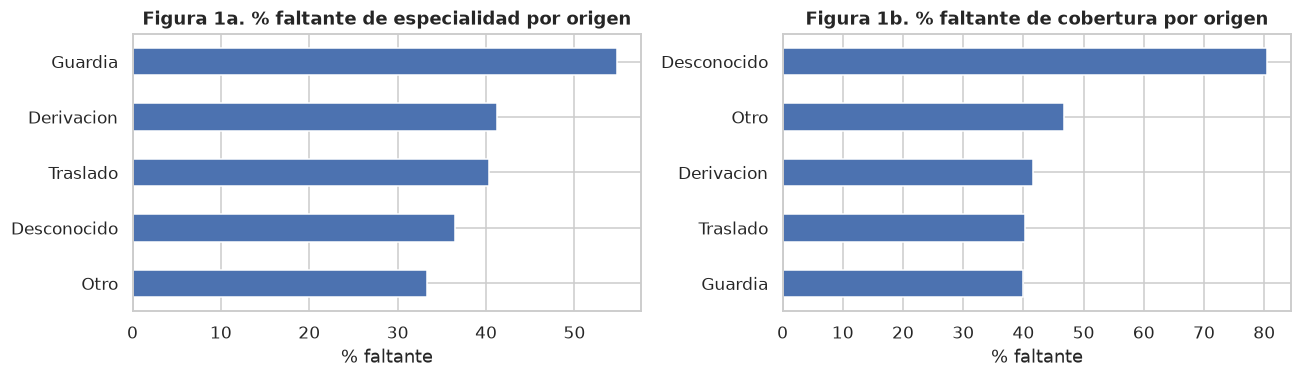

In [5]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

cov_obs = pd.get_dummies(df[["tipo_admision", "origen_admision", "diag_principal", "sexo"]], drop_first=True,
                         dtype=float).join(df[["edad", "time_in_hospital", "num_lab_procedures", "number_diagnoses"]])
cov_obs = (cov_obs - cov_obs.mean()) / cov_obs.std()
filas = []
for var, ind in [("race", "falta_raza"), ("medical_specialty", "falta_especialidad"), ("payer_code", "falta_cobertura")]:
    r = df[ind].to_numpy()
    m = LogisticRegression(C=1e6, max_iter=3000).fit(cov_obs, r)
    p1 = m.predict_proba(cov_obs)[:, 1]
    p0 = r.mean()
    ll1 = np.sum(r * np.log(p1) + (1 - r) * np.log(1 - p1))
    ll0 = np.sum(r * np.log(p0) + (1 - r) * np.log(1 - p0))
    lr = 2 * (ll1 - ll0)
    filas.append({"variable": var, "% faltante": 100 * r.mean(), "LR χ²": lr, "gl": cov_obs.shape[1],
                  "p-valor": stats.chi2.sf(lr, cov_obs.shape[1]), "AUC(falta | X)": roc_auc_score(r, p1),
                  "% reint. si falta": 100 * df.loc[r == 1, "readmit30"].mean(),
                  "% reint. si no falta": 100 * df.loc[r == 0, "readmit30"].mean()})
mec = pd.DataFrame(filas)
display(mec)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
nfig = next(FIG)
for ax, (var, ind), letra in zip(axes, [("especialidad", "falta_especialidad"), ("cobertura", "falta_cobertura")], "ab"):
    df.groupby("origen_admision")[ind].mean().mul(100).sort_values().plot.barh(ax=ax, color="#4C72B0")
    ax.set(title=f"Figura {nfig}{letra}. % faltante de {var} por origen", xlabel="% faltante", ylabel="")
plt.tight_layout()
plt.show()

**Diagnóstico y estrategia (justificada).**

| Variable | Mecanismo | Evidencia | Tratamiento |
|---|---|---|---|
| `weight` (≈97% faltante) | **MNAR** probable | se registra sólo cuando el peso es clínicamente relevante (extremo); el valor ausente depende del propio peso | **se descarta**: imputar 97% sería inventar la variable |
| `medical_specialty` (≈48%) | **MAR** | LR test rechaza MCAR (p ≈ 0); la falta depende fuertemente del origen de admisión, es decir, de cómo cada hospital carga datos | categoría `Desconocido` |
| `payer_code` (≈43%) | **MAR** | ídem; además la tasa de reinternación difiere según falte o no | categoría `Desconocido` |
| `race` (≈3%) | **MAR** | LR test rechaza MCAR; AUC moderado | categoría `Desconocido` |

**Por qué una categoría `Desconocido` y no imputación por moda ni eliminación de filas.** Bajo MAR, eliminar casos completos sesga la muestra (perderíamos el 75% de las filas, y no al azar). Imputar por la moda asignaría a la mitad de los pacientes la especialidad "Clínica Médica", creando una asociación espuria. Con la categoría explícita, el modelo estima un parámetro propio para el grupo con dato faltante: si $R$ depende de $X_{obs}$ y $X_{obs}$ está en el modelo, condicionar en $X_{obs}$ y en $R$ preserva la validez del ajuste bajo MAR. Los indicadores `falta_*` **no** se agregan además de la categoría: serían colineales perfectos con la dummy `Desconocido` (lo demostramos en §6.5).

# 3. Análisis exploratorio y estructura relacional de variables

## 3.1 Topología de variables (roles)

| Rol | Variable | Escala | Descripción |
|---|---|---|---|
| **Y** (resultado) | `readmit30` | binaria | reinternación en < 30 días (≈9%) |
| **T** (tratamiento) | `hba1c_medida` | binaria | se midió HbA1c en la internación (≈18%) |
| **M** (mediador) | `cambio_med` | binaria | cambio de medicación diabética (T → M → Y) |
| **C** (colisionador) | `num_lab_procedures` | conteo | cantidad de análisis: T → C ← gravedad → Y |
| Post-tratamiento | `time_in_hospital` | discreta 1–14 | días de internación (posterior al test) |
| **Z** numéricas | `edad`, `number_diagnoses`, `log_number_*` | continua/discreta | estado al ingreso, historial previo |
| **Z** categóricas | `sexo`, `raza`, `tipo_admision`, `origen_admision`, `especialidad`, `cobertura`, `diag_principal` | nominal | contexto de admisión |
| Otras X | `num_medications`, `num_procedures`, `insulina`, `diabetesMed` | conteo/binaria | intensidad del tratamiento |

Los códigos de admisión y diagnóstico son **nominales** (el código 7 no es "mayor" que el 1): se codifican con dummies, nunca como numéricos. La edad viene en decenios y se usa el punto medio.

## 3.2 Distribuciones: asimetría y colas pesadas

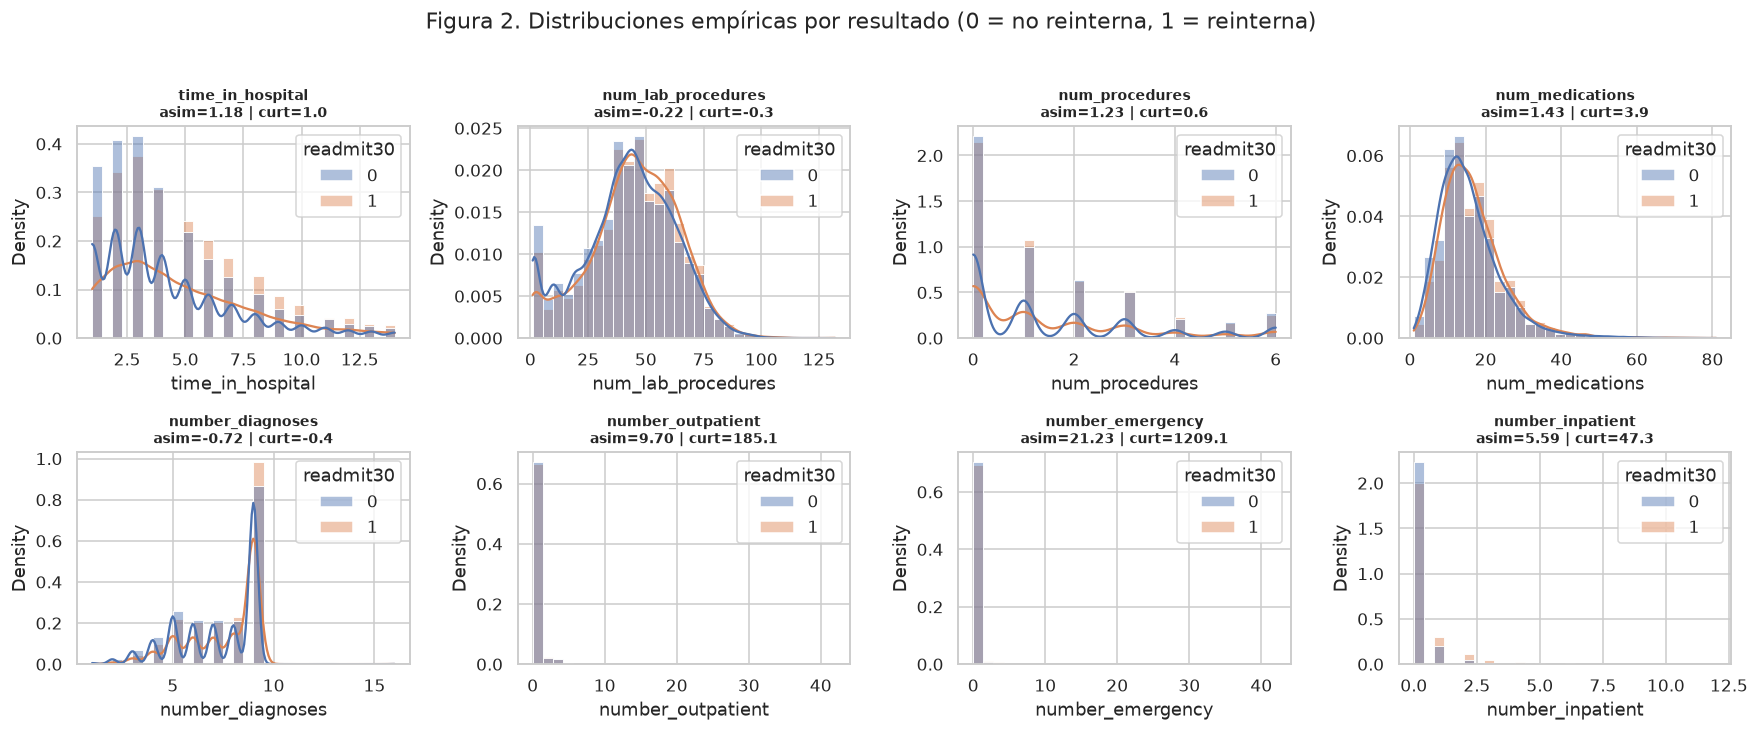

,mean,median,std,max,skew,kurt
time_in_hospital,4.2733,3.0000,2.9339,14.0000,1.1792,1.0120
num_lab_procedures,42.8764,44.0000,19.8943,132.0000,-0.2196,-0.2992
num_procedures,1.4255,1.0000,1.7571,6.0000,1.2276,0.5597
num_medications,15.6652,14.0000,8.2873,81.0000,1.4346,3.8558
number_diagnoses,7.2238,8.0000,2.0013,16.0000,-0.7246,-0.3736
number_outpatient,0.2795,0.0000,1.0641,42.0000,9.6989,185.0616
number_emergency,0.1039,0.0000,0.5119,42.0000,21.2291,"1,209.1319"
number_inpatient,0.1763,0.0000,0.6017,12.0000,5.5870,47.3287


In [6]:
num_eda = ["time_in_hospital", "num_lab_procedures", "num_procedures", "num_medications", "number_diagnoses",
           "number_outpatient", "number_emergency", "number_inpatient"]
fig, axes = plt.subplots(2, 4, figsize=(16, 6.5))
for ax, c in zip(axes.ravel(), num_eda):
    sns.histplot(data=df, x=c, hue="readmit30", stat="density", common_norm=False, kde=c in num_eda[:5],
                 bins=30, ax=ax, palette=["#4C72B0", "#DD8452"], alpha=.45)
    ax.set_title(f"{c}\nasim={df[c].skew():.2f} | curt={df[c].kurt():.1f}", fontsize=9)
fig.suptitle(f"Figura {next(FIG)}. Distribuciones empíricas por resultado (0 = no reinterna, 1 = reinterna)", y=1.02)
plt.tight_layout()
plt.show()
display(df[num_eda].agg(["mean", "median", "std", "max", "skew", "kurt"]).T)

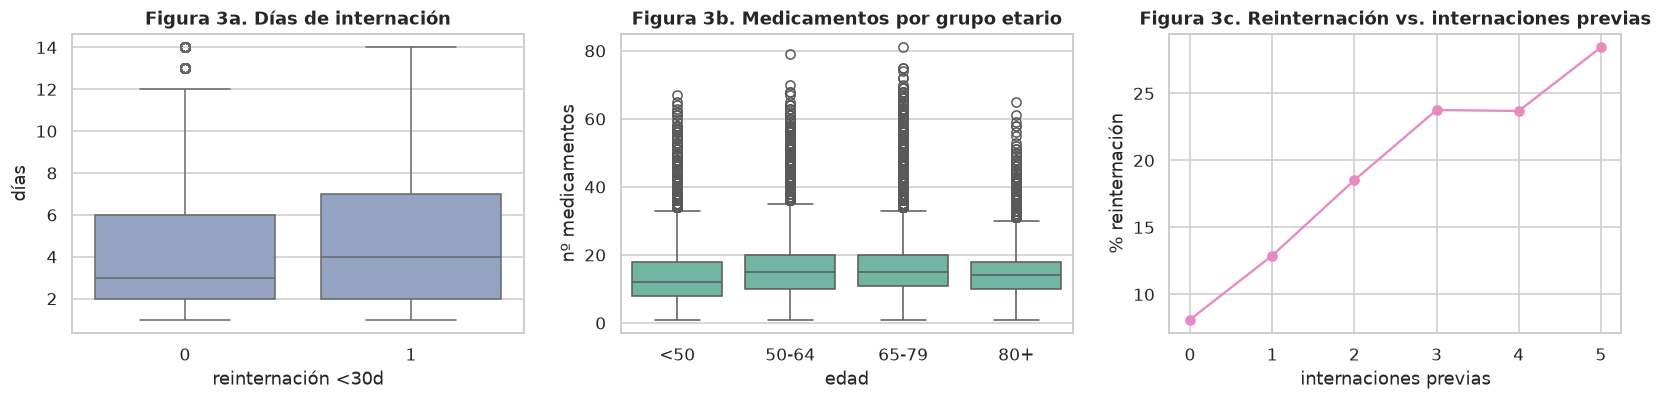

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
nfig = next(FIG)
sns.boxplot(data=df, x="readmit30", y="time_in_hospital", ax=axes[0], color="#8DA0CB")
axes[0].set(title=f"Figura {nfig}a. Días de internación", xlabel="reinternación <30d", ylabel="días")
sns.boxplot(data=df, x="edad_grupo", y="num_medications", ax=axes[1], color="#66C2A5")
axes[1].set(title=f"Figura {nfig}b. Medicamentos por grupo etario", xlabel="edad", ylabel="nº medicamentos")
df.groupby("number_inpatient").readmit30.agg(["mean", "size"]).query("size>=100")["mean"].mul(100).plot(
    marker="o", ax=axes[2], color="#E78AC3")
axes[2].set(title=f"Figura {nfig}c. Reinternación vs. internaciones previas", xlabel="internaciones previas",
            ylabel="% reinternación")
plt.tight_layout()
plt.show()

Las visitas previas tienen **colas muy pesadas** (mediana 0, curtosis de decenas a cientos): se modelan con $\log(1+x)$. La duración de la internación y los medicamentos son asimétricos a la derecha. El resultado está **desbalanceado** (9%), por lo que *accuracy* no sirve como métrica (un modelo que diga siempre "no" acierta 91%). La figura c muestra un gradiente fuerte y monótono entre internaciones previas y reinternación: será el principal predictor.

## 3.3 Asociaciones cruzadas: Pearson vs. Spearman y Cramér's V

Comparamos Pearson (lineal, sensible a colas) con Spearman (monótona, basada en rangos). Diferencias grandes entre ambas señalan relaciones no lineales o dominadas por valores extremos.

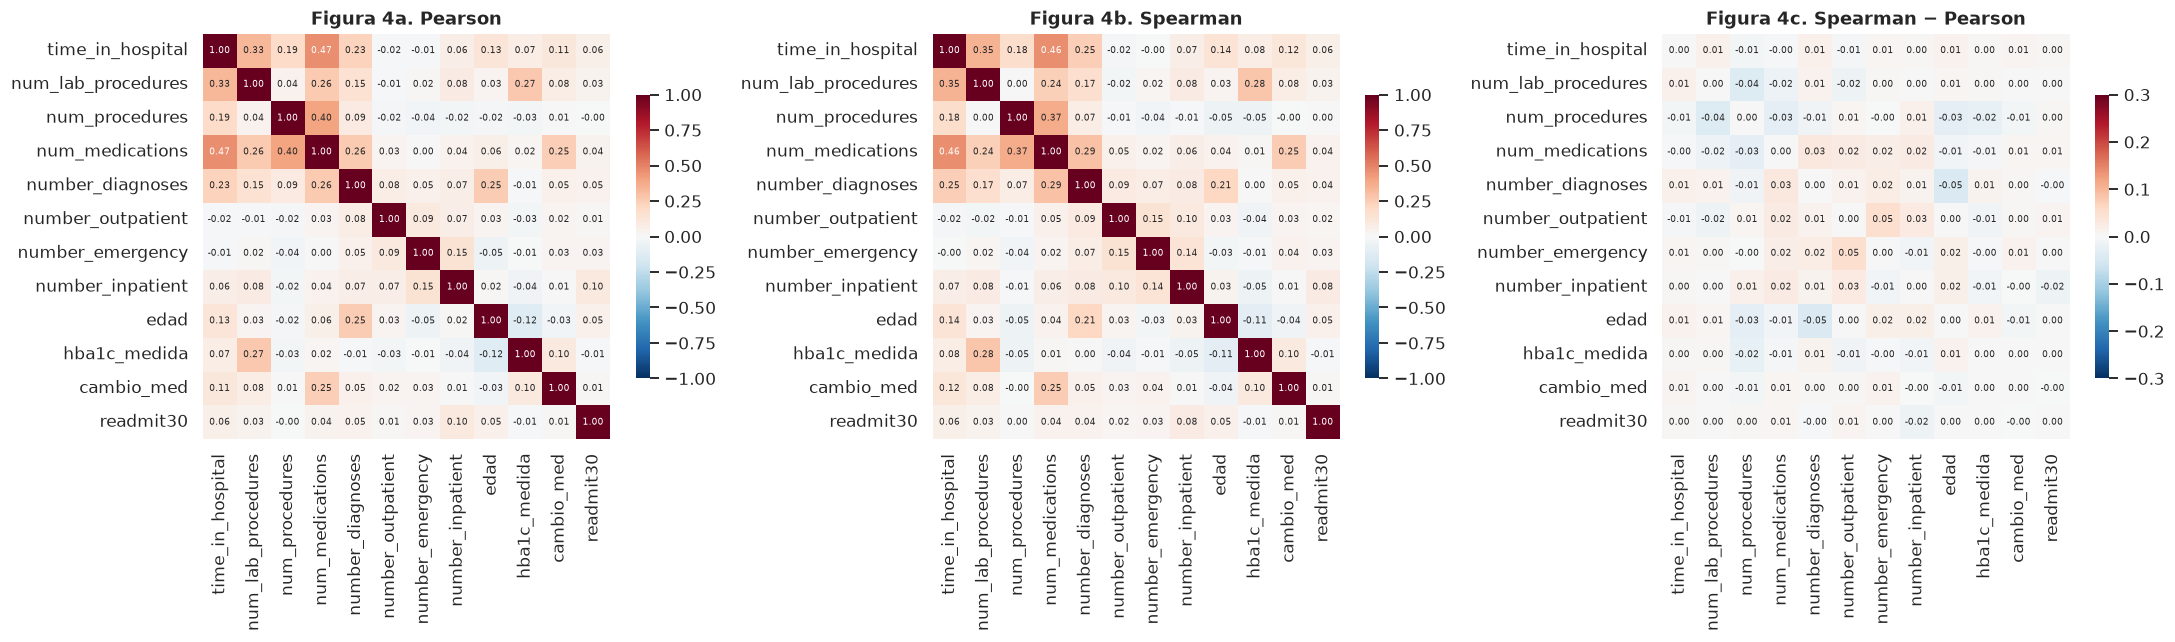

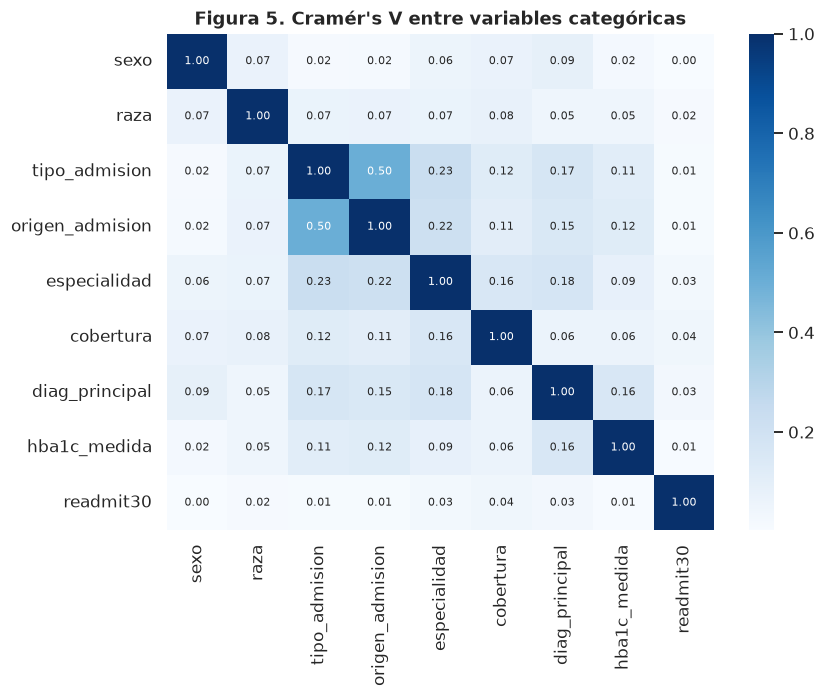

In [8]:
cols_corr = num_eda + ["edad", "hba1c_medida", "cambio_med", "readmit30"]
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
pear, spear = df[cols_corr].corr("pearson"), df[cols_corr].corr("spearman")
nfig = next(FIG)
for ax, mat, tit, letra in [(axes[0], pear, "Pearson", "a"), (axes[1], spear, "Spearman", "b"),
                            (axes[2], spear - pear, "Spearman − Pearson", "c")]:
    sns.heatmap(mat, ax=ax, cmap="RdBu_r", center=0, vmin=-1 if tit != "Spearman − Pearson" else -.3,
                vmax=1 if tit != "Spearman − Pearson" else .3, annot=True, fmt=".2f", annot_kws={"size": 6},
                cbar_kws={"shrink": .7})
    ax.set_title(f"Figura {nfig}{letra}. {tit}")
plt.tight_layout()
plt.show()


def cramers_v(a, b):
    tab = pd.crosstab(a, b)
    chi2 = stats.chi2_contingency(tab, correction=False)[0]
    n, r, k = tab.to_numpy().sum(), *tab.shape
    return np.sqrt(chi2 / (n * (min(r, k) - 1)))


cats = Z_CAT + ["hba1c_medida", "readmit30"]
cv_mat = pd.DataFrame([[cramers_v(df[a], df[b]) for b in cats] for a in cats], index=cats, columns=cats)
fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(cv_mat, annot=True, fmt=".2f", cmap="Blues", ax=ax, annot_kws={"size": 7})
ax.set_title(f"Figura {next(FIG)}. Cramér's V entre variables categóricas")
plt.tight_layout()
plt.show()

**Hallazgos no pedidos que condicionan el análisis.**

* Las diferencias Spearman − Pearson son pequeñas (|Δ| < 0,06): las relaciones son mayormente monótonas y casi lineales. Aun así, las visitas previas tienen colas extremas (curtosis de 47 a 1.209) que dan **leverage** a pocos pacientes en un modelo lineal → transformación $\log(1+x)$.
* `origen_admision` y `tipo_admision` están muy asociadas (Cramér's V ≈ 0,50): ingresar por guardia ≈ admisión de emergencia. Información en parte redundante.
* `hba1c_medida` se asocia con `diag_principal` (V ≈ 0,16), `tipo_admision` (≈ 0,11) y `especialidad` (≈ 0,09): la decisión de medir **no es aleatoria** — primera señal de confusión.
* Ninguna variable aislada se asocia fuertemente con `readmit30` (|r| ≤ 0,10; Cramér's V ≤ 0,04): anticipa una capacidad predictiva modesta.

## 3.4 Estratificación: ¿a quién se le mide HbA1c?

,Sin HbA1c (T=0),Con HbA1c (T=1),SMD
edad,66.3413,61.4321,-0.2958
time_in_hospital,4.1703,4.7313,0.1881
number_diagnoses,7.2318,7.1882,-0.0214
number_inpatient,0.1876,0.1257,-0.1087
number_emergency,0.1053,0.0976,-0.0157
emergencia,0.4851,0.6036,0.2396
diag_circ,0.3029,0.3175,0.0314
num_lab_procedures,40.3152,54.2667,0.7654


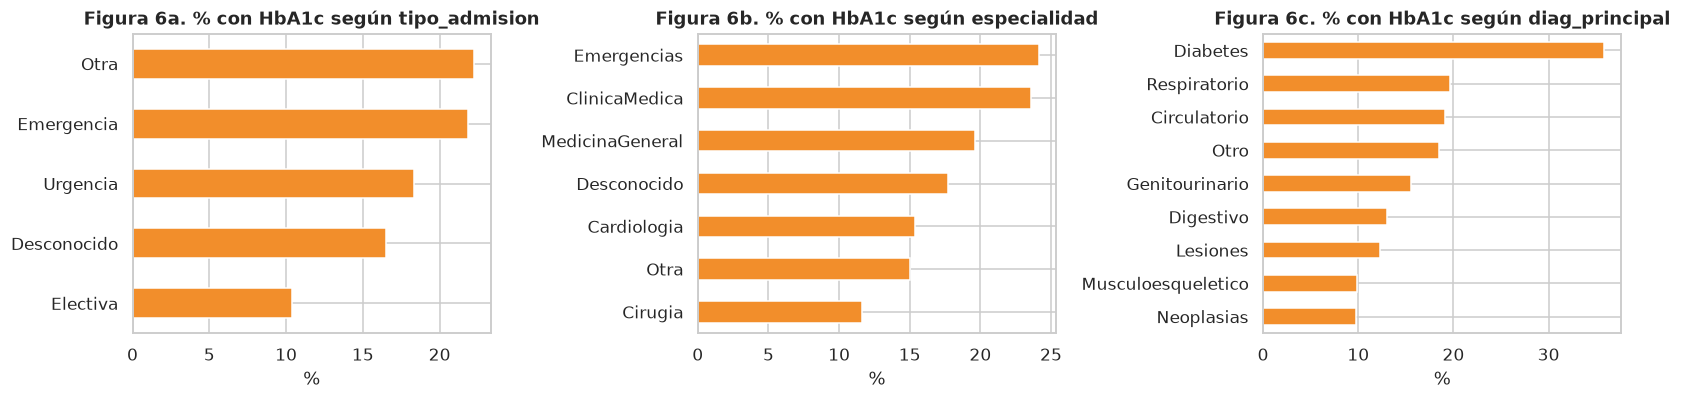

In [9]:
covs_bal = ["edad", "time_in_hospital", "number_diagnoses", "number_inpatient", "number_emergency", "emergencia",
            "diag_circ", "num_lab_procedures"]
g = df.groupby("hba1c_medida")[covs_bal].mean().T
g.columns = ["Sin HbA1c (T=0)", "Con HbA1c (T=1)"]
sd_pool = np.sqrt((df.loc[df.hba1c_medida == 1, covs_bal].var() + df.loc[df.hba1c_medida == 0, covs_bal].var()) / 2)
g["SMD"] = (g.iloc[:, 1] - g.iloc[:, 0]) / sd_pool
display(g)
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
nfig = next(FIG)
for ax, v, letra in zip(axes, ["tipo_admision", "especialidad", "diag_principal"], "abc"):
    df.groupby(v).hba1c_medida.mean().mul(100).sort_values().plot.barh(ax=ax, color="#F28E2B")
    ax.set(title=f"Figura {nfig}{letra}. % con HbA1c según {v}", xlabel="%", ylabel="")
plt.tight_layout()
plt.show()

A los pacientes con test se los **interna más días**, son más jóvenes (SMD = −0,30 en edad; el umbral habitual de desbalance es |SMD| > 0,1), ingresan más por emergencia y tienen **menos internaciones previas**. El porcentaje de medición va de 10% (neoplasias) a 36% (diabetes como diagnóstico principal) y de 12% a 24% según la especialidad. Estas mismas variables predicen la reinternación → **confusores**. Notar el SMD de **+0,77** en nº de análisis: el test *es* un análisis (arco $T \to C$ del DAG).

# 4. Fase 1 — Contrastes de hipótesis

## 4.0 Diseño: α, potencia y efecto mínimo detectable

Fijamos $\alpha = 0{,}05$ **antes** de mirar los resultados. Con muestras de decenas de miles, casi cualquier diferencia es "significativa"; por eso reportamos siempre **magnitud del efecto e IC 95%**, y calculamos la **potencia** del diseño: ¿qué diferencia mínima de reinternación podemos detectar con 80% de potencia dados los tamaños de grupo?

Para proporciones usamos la transformación arcoseno: $h = 2\arcsin\sqrt{p_1} - 2\arcsin\sqrt{p_2}$, con potencia $1-\beta = \Phi\left(|h|\sqrt{n_{ef}} - z_{1-\alpha/2}\right)$, $n_{ef} = (1/n_1 + 1/n_2)^{-1}$.

n(T=1) = 12,845 | n(T=0) = 57,125
Efecto mínimo detectable con 80% de potencia y α=0,05: 0.77 pp (de 9.10% a 8.33%)


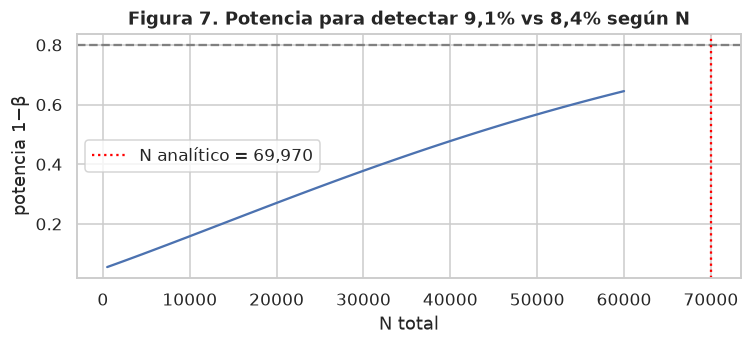

In [10]:
t1, t0 = df[df.hba1c_medida == 1], df[df.hba1c_medida == 0]
mde = S.mde_two_proportions(t0.readmit30.mean(), len(t1), len(t0))
print(f"n(T=1) = {len(t1):,} | n(T=0) = {len(t0):,}")
print(f"Efecto mínimo detectable con 80% de potencia y α=0,05: {100 * mde:.2f} pp "
      f"(de {100 * t0.readmit30.mean():.2f}% a {100 * (t0.readmit30.mean() - mde):.2f}%)")
ns = np.linspace(500, 60000, 60).astype(int)
pw = [S.power_two_proportions(0.091, 0.084, int(n * .18), int(n * .82)) for n in ns]
fig, ax = plt.subplots(figsize=(7, 3.3))
ax.plot(ns, pw, color="#4C72B0")
ax.axhline(.8, ls="--", color="gray")
ax.axvline(len(df), ls=":", color="red", label=f"N analítico = {len(df):,}")
ax.set(title=f"Figura {next(FIG)}. Potencia para detectar 9,1% vs 8,4% según N", xlabel="N total",
       ylabel="potencia 1−β")
ax.legend()
plt.tight_layout()
plt.show()

Con nuestro N, el diseño detecta diferencias de ≈ **0,8 pp** con 80% de potencia. Una diferencia de 0,7 pp (como la observada) queda en el límite: la potencia es ≈ 73%. Esto anticipa que efectos causales **menores** a ~0,8 pp no podrán distinguirse de cero — no por un mal análisis sino por un límite del diseño observacional.

## 4.1 H1 — Reinternación según medición de HbA1c (test z de dos proporciones)

$H_0: p_{T=1} = p_{T=0}$ vs. $H_1: p_{T=1} \neq p_{T=0}$. Estadístico $z = \frac{\hat p_1 - \hat p_2}{\sqrt{\bar p(1-\bar p)(1/n_1+1/n_2)}} \sim N(0,1)$ bajo $H_0$ (aproximación válida: $n\hat p > 10$ en ambos grupos). Efecto: $h$ de Cohen.

In [11]:
h1 = S.two_proportion_test(t1.readmit30.sum(), len(t1), t0.readmit30.sum(), len(t0))
print(f"p(T=1) = {100 * h1['p1']:.2f}% | p(T=0) = {100 * h1['p2']:.2f}%")
print(f"Diferencia = {100 * h1['diff']:.2f} pp | IC95% [{100 * h1['ci_low']:.2f}; {100 * h1['ci_high']:.2f}] pp")
print(f"z = {h1['z']:.3f} | p-valor = {h1['p_value']:.4f} | h de Cohen = {h1['cohen_h']:.3f}")
print(f"Decisión (α=0,05): {'se rechaza H0' if h1['p_value'] < ALPHA else 'no se rechaza H0'}")

p(T=1) = 8.39% | p(T=0) = 9.10%
Diferencia = -0.71 pp | IC95% [-1.24; -0.17] pp
z = -2.540 | p-valor = 0.0111 | h de Cohen = -0.025
Decisión (α=0,05): se rechaza H0


Se **rechaza** $H_0$ (p ≈ 0,011): los pacientes con HbA1c medida se reinternan 0,71 pp menos (IC 95%: −1,24 a −0,17). Pero el tamaño de efecto es **minúsculo** ($h = 0{,}025$, muy por debajo de 0,2, el umbral de "efecto chico") y, como vimos en §3.4, los grupos **no son comparables**. Este test responde a una pregunta asociativa; la causal se aborda en la Fase 4.

## 4.2 H2 — Duración de la internación índice: reinternados vs. no reinternados

Los días son discretos (1–14) y asimétricos (asimetría ≈ 1,1). Con $n$ grande el **TCL** garantiza la normalidad aproximada de la **media muestral**, por lo que el test t es válido para comparar medias; usamos la versión de **Welch** porque las varianzas difieren. Como complemento robusto, **Mann-Whitney U** contrasta $H_0: P(A>B) = P(B>A)$ (igualdad de distribuciones en sentido estocástico), con la correlación *rank-biserial* como efecto.

In [12]:
a, b = df.loc[df.readmit30 == 1, "time_in_hospital"], df.loc[df.readmit30 == 0, "time_in_hospital"]
h2t, h2u = S.welch_t(a, b), S.mann_whitney(a, b)
print(f"Welch t: Δmedias = {h2t['diff']:.3f} días | IC95% [{h2t['ci_low']:.3f}; {h2t['ci_high']:.3f}] | "
      f"t({h2t['df']:.0f}) = {h2t['t']:.2f} | p = {h2t['p_value']:.2e} | d de Cohen = {h2t['cohen_d']:.3f}")
print(f"Mann-Whitney: medianas {h2u['median_a']:.0f} vs {h2u['median_b']:.0f} días | U = {h2u['U']:.3e} | "
      f"p = {h2u['p_value']:.2e} | P(A>B) = {h2u['prob_superioridad']:.3f} | rank-biserial = "
      f"{h2u['rank_biserial']:.3f} IC95% [{h2u['rb_ci_low']:.3f}; {h2u['rb_ci_high']:.3f}]")

Welch t: Δmedias = 0.576 días | IC95% [0.497; 0.655] | t(7445) = 14.28 | p = 1.09e-45 | d de Cohen = 0.196
Mann-Whitney: medianas 4 vs 3 días | U = 2.239e+08 | p = 1.68e-56 | P(A>B) = 0.560 | rank-biserial = 0.120 IC95% [0.105; 0.135]


Ambos tests rechazan $H_0$: los reinternados estuvieron, en promedio, **0,58 días más** internados (IC 95%: 0,50–0,65). El efecto es chico ($d \approx 0{,}20$; un reinternado tiene 56% de probabilidad de haber tenido una internación más larga que un no reinternado). Interpretación operativa: una internación larga es un **marcador de riesgo** útil para planificar el seguimiento post-alta.

## 4.3 H3 (adicional) — Internaciones previas

Variable de cola pesada (curtosis > 20, mediana 0): el test t sería dominado por pocos pacientes extremos. Usamos sólo Mann-Whitney.

In [13]:
a3, b3 = df.loc[df.readmit30 == 1, "number_inpatient"], df.loc[df.readmit30 == 0, "number_inpatient"]
h3 = S.mann_whitney(a3, b3)
print(f"Media {a3.mean():.3f} vs {b3.mean():.3f} | % con ≥1 previa: {100 * (a3 > 0).mean():.1f}% vs {100 * (b3 > 0).mean():.1f}%")
print(f"U = {h3['U']:.3e} | p = {h3['p_value']:.2e} | rank-biserial = {h3['rank_biserial']:.3f} "
      f"IC95% [{h3['rb_ci_low']:.3f}; {h3['rb_ci_high']:.3f}]")

Media 0.369 vs 0.157 | % con ≥1 previa: 20.1% vs 10.9%
U = 2.190e+08 | p = 1.95e-111 | rank-biserial = 0.096 IC95% [0.080; 0.111]


# 5. Fase 1 — ANOVA de un factor: polifarmacia por grupo etario

**Pregunta de negocio:** la cantidad de medicamentos administrados es un *driver* del costo de farmacia y del riesgo de interacciones. ¿Difiere entre grupos etarios?

Modelo: $Y_{ij} = \mu + \alpha_i + \varepsilon_{ij}$, $i \in \{<50, 50\text{–}64, 65\text{–}79, 80+\}$. $H_0: \mu_1 = \mu_2 = \mu_3 = \mu_4$ vs. $H_1$: al menos una media difiere. Supuestos: independencia (garantizada por un paciente por fila), normalidad dentro de grupos, homocedasticidad.

## 5.1 Normalidad: el problema de Shapiro-Wilk con N grande

Con $N \geq 1.500$, Shapiro-Wilk rechaza ante desvíos **irrelevantes** para el TCL: su potencia crece con $n$ y detecta cualquier imperfección. Lo mostramos con un experimento: aplicamos Shapiro a datos simulados de una distribución **casi** normal (Gamma con forma 100, asimetría ≈ 0,2) de tamaño creciente: con n chico no rechaza; con n = 5.000 rechaza, aunque la forma de la distribución sea la misma.

In [14]:
rng = np.random.default_rng(SEED)
# Gamma(k=100): asimetría 0,2 — desvío irrelevante para el TCL
sim_sh = pd.DataFrame([{"n": n, "asimetría": stats.skew(x := rng.gamma(100, 1, n)), "p Shapiro": stats.shapiro(x)[1]}
                       for n in [50, 200, 1000, 5000]])
display(sim_sh)
grupos_anova = {k: v.num_medications.to_numpy() for k, v in df.groupby("edad_grupo", observed=True)}
display(S.normality_summary(grupos_anova))

,n,asimetría,p Shapiro
0,50,-0.0458,0.3171
1,200,0.2696,0.3629
2,1000,0.1637,0.0757
3,5000,0.1999,0.0000


,grupo,n,media,desvío,asimetría,curtosis_exceso,|asim|<=1,Shapiro p (n=5000),Shapiro p (n=500)
0,<50,11328,13.7597,7.8832,1.4314,3.9126,False,0.0000,0.0000
1,50-64,12349,16.1593,8.8179,1.4549,3.6042,False,0.0000,0.0000
2,65-79,33431,16.4890,8.5408,1.4766,3.9209,False,0.0000,0.0000
3,80+,12862,14.7280,6.9692,1.0374,2.1985,False,0.0000,0.0000


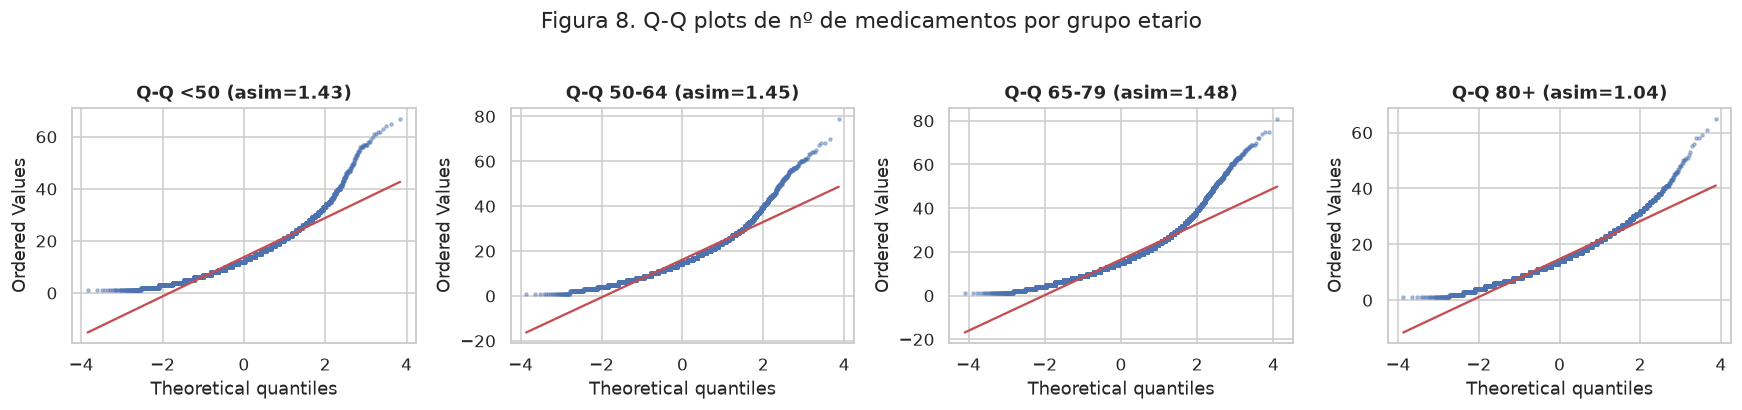

In [15]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.6))
for ax, (k, x) in zip(axes, grupos_anova.items()):
    stats.probplot(x, dist="norm", plot=ax)
    ax.get_lines()[0].set(markersize=2, alpha=.4)
    ax.set_title(f"Q-Q {k} (asim={stats.skew(x):.2f})")
fig.suptitle(f"Figura {next(FIG)}. Q-Q plots de nº de medicamentos por grupo etario", y=1.03)
plt.tight_layout()
plt.show()

Shapiro rechaza en todos los grupos (incluso en submuestras de 500), pero el criterio práctico de la cátedra es asimetría $\in [-1, 1]$: estamos **levemente por encima** (≈1,0–1,5) con cola derecha visible en los Q-Q plots. Con $n_i > 11.000$ por grupo, el TCL hace que las **medias** sean normales, por lo que el F es robusto a esta asimetría moderada. Igualmente reportaremos Kruskal-Wallis como contraste no paramétrico.

## 5.2 Homocedasticidad (Levene) y elección del test

In [16]:
lev = stats.levene(*grupos_anova.values(), center="median")
print(f"Levene (Brown-Forsythe, centrado en la mediana): W = {lev.statistic:.2f} | p = {lev.pvalue:.2e}")
print("Desvíos por grupo:", {k: round(x.std(ddof=1), 2) for k, x in grupos_anova.items()})
f_cl = stats.f_oneway(*grupos_anova.values())
f_w = S.welch_anova(*grupos_anova.values())
kw = stats.kruskal(*grupos_anova.values())
ef = S.anova_effect_sizes(*grupos_anova.values())
anova_tab = pd.DataFrame([
    {"Test": "ANOVA clásico (F de Fisher)", "Estadístico": f_cl.statistic, "gl": f"3, {len(df) - 4}", "p-valor": f_cl.pvalue},
    {"Test": "ANOVA de Welch", "Estadístico": f_w["F"], "gl": f"3, {f_w['df2']:.0f}", "p-valor": f_w["p_value"]},
    {"Test": "Kruskal-Wallis (H)", "Estadístico": kw.statistic, "gl": "3", "p-valor": kw.pvalue}])
display(anova_tab)
print(f"η² = {ef['eta2']:.4f} | ω² = {ef['omega2']:.4f}")

Levene (Brown-Forsythe, centrado en la mediana): W = 104.50 | p = 1.70e-67
Desvíos por grupo: {'<50': np.float64(7.88), '50-64': np.float64(8.82), '65-79': np.float64(8.54), '80+': np.float64(6.97)}


,Test,Estadístico,gl,p-valor
0,ANOVA clásico (F de Fisher),385.4456,"3, 69966",0.0000
1,ANOVA de Welch,408.6218,"3, 28932",0.0000
2,Kruskal-Wallis (H),"1,226.0248",3,0.0000


η² = 0.0163 | ω² = 0.0162


Levene **rechaza** la homocedasticidad (desvíos de 7,0 a 8,8): el F clásico no es confiable. **Elegimos Welch** como test principal (no asume varianzas iguales y es robusto a asimetría moderada con $n$ grande) y Kruskal-Wallis como confirmación no paramétrica. ¿Por qué Welch y no sólo Kruskal-Wallis? Porque la pregunta de negocio es sobre la **media** de medicamentos (lo que determina el costo total), y Kruskal-Wallis contrasta otra hipótesis (dominancia estocástica).

Los tres tests rechazan $H_0$ con p ≈ 0. Pero $\eta^2 \approx 0{,}016$: la edad explica **apenas 1,6%** de la variabilidad en la cantidad de medicamentos. **Significativo no es lo mismo que relevante.**

## 5.3 Comparaciones múltiples post-hoc

Con 4 grupos hay 6 comparaciones; sin corrección, la probabilidad de al menos un falso positivo sería $1-(0{,}95)^6 \approx 26\%$. Comparamos tres procedimientos que controlan la tasa de error por familia (FWER):

* **Tukey HSD:** asume varianzas iguales (violado aquí).
* **Games-Howell:** versión de Tukey para varianzas desiguales (gl de Welch) → **nuestra elección**.
* **Bonferroni:** $p_{aj} = \min(m \cdot p, 1)$, conservador.

In [17]:
gh = S.games_howell(grupos_anova)
bf = S.bonferroni_pairwise(grupos_anova)
tk = stats.tukey_hsd(*grupos_anova.values())
keys = list(grupos_anova)
gh["p_Tukey"] = [tk.pvalue[keys.index(r.A), keys.index(r.B)] for r in gh.itertuples()]
gh["p_Bonferroni"] = bf["p_bonferroni"].to_numpy()
display(gh.rename(columns={"p_ajustado": "p_Games-Howell"}))

,A,B,dif_medias,q,df,p_Games-Howell,p_Tukey,p_Bonferroni
0,<50,50-64,-2.3996,31.2630,"23,659.3801",0.0000,0.0000,0.0000
1,<50,65-79,-2.7293,44.0780,"21,003.4939",0.0000,0.0000,0.0000
2,<50,80+,-0.9683,14.2292,"22,781.0695",0.0000,0.0000,0.0000
3,50-64,65-79,-0.3297,5.0637,"21,438.0058",0.0019,0.0008,0.0021
4,50-64,80+,1.4312,20.1677,"23,488.8242",0.0000,0.0000,0.0000
5,65-79,80+,1.7609,32.2628,"28,373.2766",0.0000,0.0000,0.0000


Todos los pares difieren con los tres métodos. El patrón es **no monótono**: la polifarmacia sube de <50 a 50–79 años (+2,4 a +2,7 medicamentos) y **baja** en ≥80 (−1,8 respecto de 65–79). Hipótesis operativa adicional: en los muy mayores se tiende a simplificar esquemas (des-prescripción) o predominan internaciones más cortas. La diferencia 50–64 vs 65–79 (0,33 medicamentos) es estadísticamente significativa pero clínicamente irrelevante.

# 6. Fase 2 — Regresión lineal clásica y diagnóstico de Gauss-Markov

**Pregunta P5:** ¿qué explica la **duración de la internación** (días-cama, el recurso más caro)? Modelo de referencia por MCO, estimado sólo en el conjunto de **entrenamiento** (el mismo 80% que usaremos en la Fase 3; el test queda intacto):

$$\text{días}_i = \beta_0 + \beta_1\,\text{análisis}_i + \beta_2\,\text{procedimientos}_i + \beta_3\,\text{medicamentos}_i + \beta_4\,\text{diagnósticos}_i + \beta_5\,\text{edad}_i + \sum_k \gamma_k\,\text{historial}_{ik} + \delta\,\text{emergencia}_i + \sum_j \lambda_j\,\text{diag}_{ij} + \varepsilon_i$$

con $\hat\beta = (X'X)^{-1}X'y$ (implementado vía descomposición QR en `tpi.stats.ols`). Bajo Gauss-Markov ($E[\varepsilon|X]=0$, $Var(\varepsilon|X)=\sigma^2 I$), $\hat\beta$ es MELI. Ordenamos las filas por `encounter_id` (proxy temporal) para poder evaluar autocorrelación.

In [18]:
Xtr_all, Xte_all, ytr_all, yte_all = Mdl.split(df)
tr = df.loc[Xtr_all.index].sort_values("encounter_id")
ols_vars = ["num_lab_procedures", "num_procedures", "num_medications", "number_diagnoses", "edad",
            "log_number_inpatient", "log_number_emergency", "log_number_outpatient", "emergencia"]
X_ols = pd.concat([tr[ols_vars].astype(float),
                   pd.get_dummies(tr.diag_principal, prefix="diag", dtype=float).drop(columns="diag_Circulatorio")], axis=1)
m_los = S.ols(X_ols, tr.time_in_hospital)
print(f"n = {m_los.n:,} | p = {m_los.p} | R² = {m_los.r2:.4f} | R² ajustado = {m_los.r2_adj:.4f} | "
      f"F({m_los.p - 1}, {m_los.n - m_los.p}) = {m_los.F:,.1f} | p(F) = {m_los.F_p:.2e}")
display(m_los.table())

n = 55,976 | p = 18 | R² = 0.3110 | R² ajustado = 0.3108 | F(17, 55958) = 1,486.0 | p(F) = 0.00e+00


,coef,se,t,p_value,ci_low,ci_high
const,-1.8730,0.0617,-30.3750,0.0000,-1.9939,-1.7522
num_lab_procedures,0.0301,0.0006,53.2719,0.0000,0.0290,0.0312
num_procedures,0.0788,0.0069,11.4586,0.0000,0.0653,0.0923
num_medications,0.1413,0.0015,95.4087,0.0000,0.1384,0.1442
number_diagnoses,0.1100,0.0056,19.5222,0.0000,0.0989,0.1210
edad,0.0199,0.0007,28.7958,0.0000,0.0185,0.0212
log_number_inpatient,0.2628,0.0355,7.4065,0.0000,0.1933,0.3324
log_number_emergency,-0.2152,0.0458,-4.7043,0.0000,-0.3049,-0.1256
log_number_outpatient,-0.3479,0.0278,-12.5337,0.0000,-0.4023,-0.2935
emergencia,0.0202,0.0223,0.9020,0.3671,-0.0236,0.0639


El modelo es globalmente significativo (F ≫ 1) y explica **~31%** de la variabilidad en días de internación. Cada medicamento adicional se asocia a +0,14 días y cada 10 análisis a +0,3 días (estas variables son en parte **consecuencia** de internaciones largas: los coeficientes son asociativos, no causales). Pacientes con diagnóstico principal de diabetes o neoplasias tienen estadías ~1 día más largas que los circulatorios, a igualdad del resto.

## 6.1 Homocedasticidad: residuos vs. ajustados, Breusch-Pagan y White

Breusch-Pagan (Koenker): LM = 2,246.0, gl = 17, p = 0.00e+00
White (cuadrados): LM = 1,791.3, gl = 18, p = 0.00e+00
Jarque-Bera: JB = 15,893.3, p = 0.00e+00 | asimetría = 1.062 | curtosis = 4.518
Durbin-Watson (orden por encounter_id) = 1.907


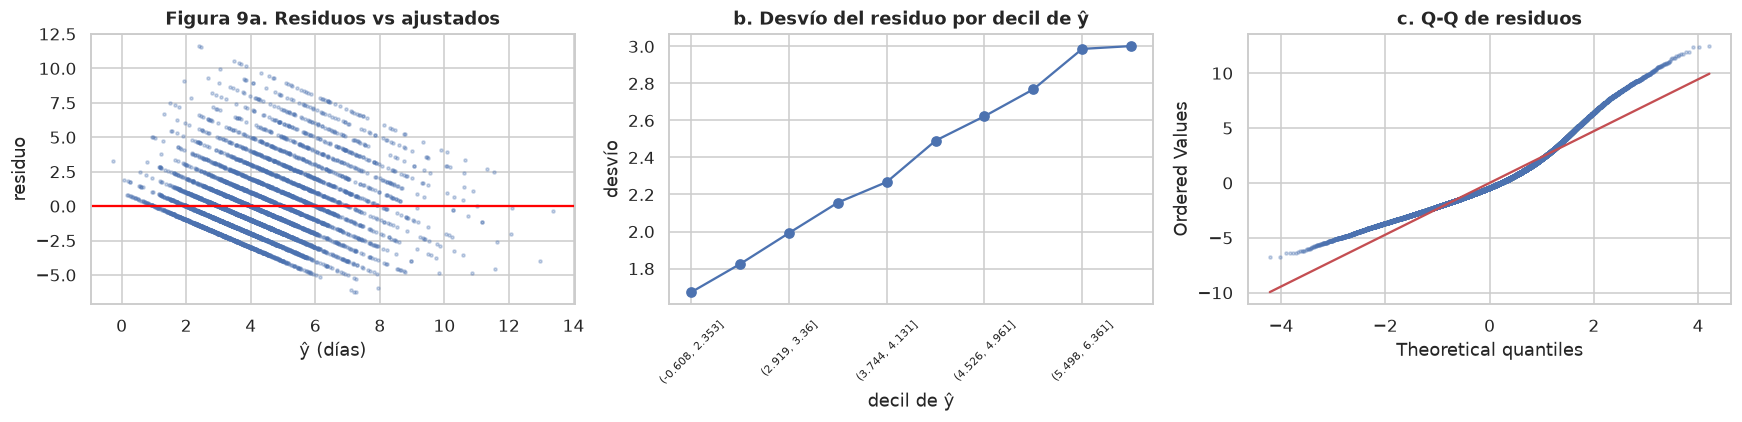

In [19]:
bp, wh = S.breusch_pagan(m_los, X_ols.to_numpy(float)), S.white_test(m_los, tr[ols_vars].to_numpy(float))
jb, dw = S.jarque_bera(m_los.resid), S.durbin_watson(m_los.resid)
print(f"Breusch-Pagan (Koenker): LM = {bp['LM']:,.1f}, gl = {bp['df']}, p = {bp['p_value']:.2e}")
print(f"White (cuadrados): LM = {wh['LM']:,.1f}, gl = {wh['df']}, p = {wh['p_value']:.2e}")
print(f"Jarque-Bera: JB = {jb['JB']:,.1f}, p = {jb['p_value']:.2e} | asimetría = {jb['asimetria']:.3f} | "
      f"curtosis = {jb['curtosis']:.3f}")
print(f"Durbin-Watson (orden por encounter_id) = {dw:.3f}")

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
idx = np.random.default_rng(SEED).choice(m_los.n, 6000, replace=False)
axes[0].scatter(m_los.fitted[idx], m_los.resid[idx], s=4, alpha=.3)
axes[0].axhline(0, color="red")
axes[0].set(title=f"Figura {next(FIG)}a. Residuos vs ajustados", xlabel="ŷ (días)", ylabel="residuo")
bins = pd.qcut(m_los.fitted, 10)
pd.Series(m_los.resid).groupby(bins, observed=True).std().plot(ax=axes[1], marker="o")
axes[1].set(title="b. Desvío del residuo por decil de ŷ", xlabel="decil de ŷ", ylabel="desvío")
axes[1].tick_params(axis="x", rotation=45, labelsize=7)
stats.probplot(m_los.resid, plot=axes[2])
axes[2].get_lines()[0].set(markersize=2, alpha=.3)
axes[2].set_title("c. Q-Q de residuos")
plt.tight_layout()
plt.show()

* **Heterocedasticidad severa:** BP y White rechazan con p ≈ 0 y la figura b muestra el **embudo**: el desvío del residuo crece de 1,7 a 3,0 días entre el primer y el último decil de $\hat y$. Además el *cutoff* físico (1 ≤ días ≤ 14) acota los residuos. Consecuencia: $\hat\beta$ sigue siendo insesgado, pero los **errores estándar clásicos son incorrectos**.
* **No normalidad:** JB rechaza; asimetría ≈ 1,06 y curtosis ≈ 4,5 (cola derecha). Con $n$ grande no invalida la inferencia sobre $\beta$ (TCL), pero indica que la escala es inadecuada.
* **Independencia:** DW ≈ 1,91, cercano a 2: autocorrelación temporal despreciable (esperable, un paciente por fila).

## 6.2 Observaciones extremas: residuos, leverage y distancia de Cook

* Residuo estudentizado externamente: $t_i = \frac{e_i}{s_{(i)}\sqrt{1-h_{ii}}}$, outlier si $|t_i|>3$.
* Leverage $h_{ii} = [X(X'X)^{-1}X']_{ii}$, alto si $h_{ii} > 2(p+1)/n$.
* Cook: $D_i = \frac{e_i^2}{p\,\hat\sigma^2}\frac{h_{ii}}{(1-h_{ii})^2}$, influyente si $D_i > 4/n$ o $D_i > 0{,}5$.

,n,%
|t_i| > 3 (outlier en Y),748,1.3363
h_ii > 2p/n = 0.00064 (leverage),2636,4.7092
D_i > 4/n = 0.000071,3163,5.6506
"D_i > 0,5",0,0.0000


Cook máximo = 0.00151


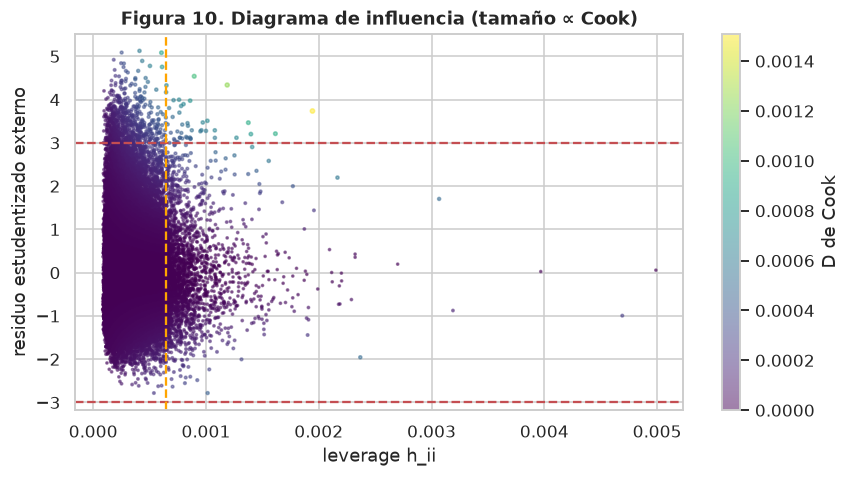

,time_in_hospital,num_medications,num_lab_procedures,num_procedures,number_inpatient,number_emergency,diag_principal,cook,lev
31020,11,9,43,0,2,8,Digestivo,0.0015,0.0019
25126,14,21,16,2,0,3,Diabetes,0.0012,0.0012
62626,14,14,11,0,3,2,Otro,0.0010,0.0009
58582,14,30,38,1,8,2,Diabetes,0.0009,0.0016
5972,13,12,63,0,1,6,Otro,0.0009,0.0014
32095,14,7,18,2,0,0,Respiratorio,0.0009,0.0006
53160,12,20,53,0,1,6,Circulatorio,0.0008,0.0014
39163,13,6,44,0,0,0,Genitourinario,0.0008,0.0006


In [20]:
inf = S.influence(m_los)
n_, p_ = m_los.n, m_los.p
crit = {"|t_i| > 3 (outlier en Y)": (inf.resid_stud_ext.abs() > 3),
        f"h_ii > 2p/n = {2 * p_ / n_:.5f} (leverage)": inf.leverage > 2 * p_ / n_,
        f"D_i > 4/n = {4 / n_:.6f}": inf.cook > 4 / n_, "D_i > 0,5": inf.cook > .5}
display(pd.DataFrame({"n": {k: int(v.sum()) for k, v in crit.items()},
                      "%": {k: 100 * v.mean() for k, v in crit.items()}}))
print(f"Cook máximo = {inf.cook.max():.5f}")
fig, ax = plt.subplots(figsize=(8, 4.5))
sc = ax.scatter(inf.leverage, inf.resid_stud_ext, s=2 + 4000 * inf.cook, c=inf.cook, cmap="viridis", alpha=.5)
ax.axhline(3, ls="--", color="r")
ax.axhline(-3, ls="--", color="r")
ax.axvline(2 * p_ / n_, ls="--", color="orange")
ax.set(title=f"Figura {next(FIG)}. Diagrama de influencia (tamaño ∝ Cook)", xlabel="leverage h_ii",
       ylabel="residuo estudentizado externo")
plt.colorbar(sc, label="D de Cook")
plt.tight_layout()
plt.show()

top = tr.assign(cook=inf.cook.to_numpy(), lev=inf.leverage.to_numpy()).nlargest(8, "cook")
display(top[["time_in_hospital", "num_medications", "num_lab_procedures", "num_procedures", "number_inpatient",
             "number_emergency", "diag_principal", "cook", "lev"]])

**¿Errores de medición o casos reales?** Ninguna observación supera $D_i > 0{,}5$ (máximo = 0,0015): con 56.000 filas ningún paciente individual mueve la recta. Los casos de mayor influencia combinan alto leverage (decenas de visitas a guardia o internaciones previas) con estadías largas: son **pacientes reales de alta complejidad**, no errores de carga (los valores están dentro del dominio físico: ≤ 14 días, ≤ 81 medicamentos). No corresponde borrarlos. Lo que sí corresponde es verificar que los resultados no dependan de ellos → regresión robusta.

## 6.3 Modelos de resguardo: escala log, HC3 y regresión robusta

In [21]:
from sklearn.linear_model import HuberRegressor, LinearRegression, RANSACRegressor

m_log = S.ols(X_ols, np.log(tr.time_in_hospital))
bp_log, jb_log = S.breusch_pagan(m_log, X_ols.to_numpy(float)), S.jarque_bera(m_log.resid)
inf_log = S.influence(m_log)
diag_cmp = pd.DataFrame({
    "MCO días": [m_los.r2_adj, bp["LM"], jb["JB"], jb["asimetria"], (inf.resid_stud_ext.abs() > 3).sum(),
                 (inf.cook > 4 / n_).sum()],
    "MCO log(días)": [m_log.r2_adj, bp_log["LM"], jb_log["JB"], jb_log["asimetria"],
                      (inf_log.resid_stud_ext.abs() > 3).sum(), (inf_log.cook > 4 / n_).sum()]},
    index=["R² ajustado", "Breusch-Pagan LM", "Jarque-Bera", "asimetría residuos", "outliers |t|>3", "Cook > 4/n"])
display(diag_cmp)

Xs = (X_ols - X_ols.mean()) / X_ols.std()
huber = HuberRegressor(epsilon=1.35, max_iter=2000).fit(Xs, tr.time_in_hospital)
ransac = RANSACRegressor(LinearRegression(), random_state=SEED, min_samples=0.5).fit(Xs, tr.time_in_hospital)
sin_inf = (inf.cook <= 4 / n_).to_numpy()
m_sin = S.ols(X_ols[sin_inf], tr.time_in_hospital[sin_inf])
coefs = pd.DataFrame({
    "MCO (SE clásico)": m_los.beta[1:], "SE clásico": m_los.se[1:], "SE HC3": m_los.se_hc3[1:],
    "MCO sin Cook>4/n": m_sin.beta[1:], "Huber": huber.coef_ / X_ols.std().to_numpy(),
    "RANSAC": ransac.estimator_.coef_ / X_ols.std().to_numpy()}, index=X_ols.columns)
coefs["ratio SE HC3/clásico"] = coefs["SE HC3"] / coefs["SE clásico"]
display(coefs.head(9))

,MCO días,MCO log(días)
R² ajustado,0.3108,0.3078
Breusch-Pagan LM,"2,246.0197","1,253.8897"
Jarque-Bera,"15,893.3124",354.6192
asimetría residuos,1.0618,-0.1303
outliers |t|>3,748.0000,39.0000
Cook > 4/n,"3,163.0000","2,608.0000"


,MCO (SE clásico),SE clásico,SE HC3,MCO sin Cook>4/n,Huber,RANSAC,ratio SE HC3/clásico
num_lab_procedures,0.0301,0.0006,0.0006,0.0297,0.0286,0.0291,1.0312
num_procedures,0.0788,0.0069,0.0073,0.0329,0.0467,0.0624,1.0595
num_medications,0.1413,0.0015,0.0016,0.1405,0.1400,0.1460,1.0961
number_diagnoses,0.1100,0.0056,0.0054,0.0890,0.0882,0.0985,0.9595
edad,0.0199,0.0007,0.0007,0.0180,0.0172,0.0191,1.0002
log_number_inpatient,0.2628,0.0355,0.0402,0.0818,0.1502,0.1648,1.1339
log_number_emergency,-0.2152,0.0458,0.0457,-0.3027,-0.1975,-0.1953,0.9984
log_number_outpatient,-0.3479,0.0278,0.0262,-0.3811,-0.2904,-0.3301,0.9448
emergencia,0.0202,0.0223,0.0227,0.0465,0.0503,0.0057,1.0167


* **log(días)** corrige casi por completo la asimetría (de 1,06 a −0,13), baja Jarque-Bera de ~15.900 a ~350 y los outliers de 748 a 39, con el mismo $R^2$; la heterocedasticidad baja a casi la mitad (BP de 2.246 a 1.254) pero persiste → se reportan **errores HC3** (MacKinnon-White). En este modelo los HC3 son hasta 13% mayores que los clásicos (internaciones previas): con $n$ grande la corrección es modesta, pero es la que garantiza IC válidos. Interpretación en escala log: cada medicamento adicional se asocia a ≈ +3,4% de días.
* **Robustez:** Huber, RANSAC y el MCO sin los puntos con Cook > 4/n mantienen el **signo** de todos los coeficientes y la magnitud de los principales (medicamentos, análisis, edad, diagnósticos). El que más cambia es el de internaciones previas (0,26 → 0,08–0,16): su efecto en MCO está empujado por los pocos pacientes con muchas internaciones (colas pesadas), por lo que reportamos el rango y no el valor puntual.

## 6.4 Multicolinealidad: VIF

$VIF_j = 1/(1-R_j^2)$, donde $R_j^2$ es el de regresar $X_j$ sobre los demás predictores.

In [22]:
vif_base = S.vif(tr[ols_vars].astype(float))
display(vif_base.to_frame())
# Experimento: agregar indicadores de faltante además de la categoría "Desconocido"
X_col = pd.concat([tr[ols_vars + ["falta_cobertura", "falta_especialidad"]].astype(float),
                   pd.get_dummies(tr[["cobertura", "especialidad"]], dtype=float)
                   .drop(columns=["cobertura_Medicare", "especialidad_ClinicaMedica"])], axis=1)
with np.errstate(divide="ignore"):
    vif_col = S.vif(X_col)
display(vif_col.head(6).to_frame())

,VIF
num_medications,1.3709
num_procedures,1.2483
number_diagnoses,1.1844
num_lab_procedures,1.1659
emergencia,1.1412
edad,1.0776
log_number_emergency,1.0516
log_number_inpatient,1.0434
log_number_outpatient,1.0338


/content/TPI_HbA1c_reinternacion/src/tpi/stats.py:228: RuntimeWarning: invalid value encountered in sqrt
  se_hc3 = np.sqrt(np.diag(XtX_inv @ meat @ XtX_inv))
/content/TPI_HbA1c_reinternacion/src/tpi/stats.py:228: RuntimeWarning: invalid value encountered in sqrt
  se_hc3 = np.sqrt(np.diag(XtX_inv @ meat @ XtX_inv))
/content/TPI_HbA1c_reinternacion/src/tpi/stats.py:228: RuntimeWarning: invalid value encountered in sqrt
  se_hc3 = np.sqrt(np.diag(XtX_inv @ meat @ XtX_inv))
/content/TPI_HbA1c_reinternacion/src/tpi/stats.py:228: RuntimeWarning: invalid value encountered in sqrt
  se_hc3 = np.sqrt(np.diag(XtX_inv @ meat @ XtX_inv))
/content/TPI_HbA1c_reinternacion/src/tpi/stats.py:228: RuntimeWarning: invalid value encountered in sqrt
  se_hc3 = np.sqrt(np.diag(XtX_inv @ meat @ XtX_inv))
/content/TPI_HbA1c_reinternacion/src/tpi/stats.py:228: RuntimeWarning: invalid value encountered in sqrt
  se_hc3 = np.sqrt(np.diag(XtX_inv @ meat @ XtX_inv))
/content/TPI_HbA1c_reinternacion/src/tpi/stats

,VIF
falta_especialidad,inf
especialidad_Desconocido,inf
falta_cobertura,inf
cobertura_Desconocido,inf
especialidad_Otra,1.7277
cobertura_Privada,1.5642


* En el modelo base **todos los VIF < 1,4**: las variables de intensidad de la internación están correlacionadas (medicamentos–días r ≈ 0,47) pero ninguna es combinación lineal de las otras. No hay inflación relevante de varianzas.
* **Multicolinealidad estructural (experimento fallido documentado en la bitácora):** si además de la categoría `Desconocido` se agregan los indicadores `falta_cobertura` y `falta_especialidad`, el VIF es **infinito**: `falta_cobertura` es idéntica a la dummy `cobertura_Desconocido` ($R_j^2 = 1$, $X'X$ singular). **Resolución:** eliminar los indicadores (la información ya está en la categoría). En la Fase 3, la regularización Ridge resolvería lo mismo de forma automática, y en los árboles es irrelevante.

## 6.5 Reducción de dimensionalidad: PCA sin *data leakage*

**Regla:** el escalado ($\mu$, $\sigma$) y la descomposición espectral $\Sigma = V\Lambda V'$ se estiman **sólo en Train**; Test se proyecta "a ciegas" con la misma matriz de rotación $V$. Si se estandarizara con la media de toda la base, información del test se filtraría al entrenamiento.

Autovalores λ_k: [2.08  1.309 1.133 1.015 0.868 0.823 0.689 0.627 0.457]
Kaiser (λ>1): 4 componentes | varianza acumulada: 61.5%
Control de fuga — media de PC1 en Train: 3.15e-17 (≈0 por construcción) | en Test: 0.0045 (≠0: proyección ciega)


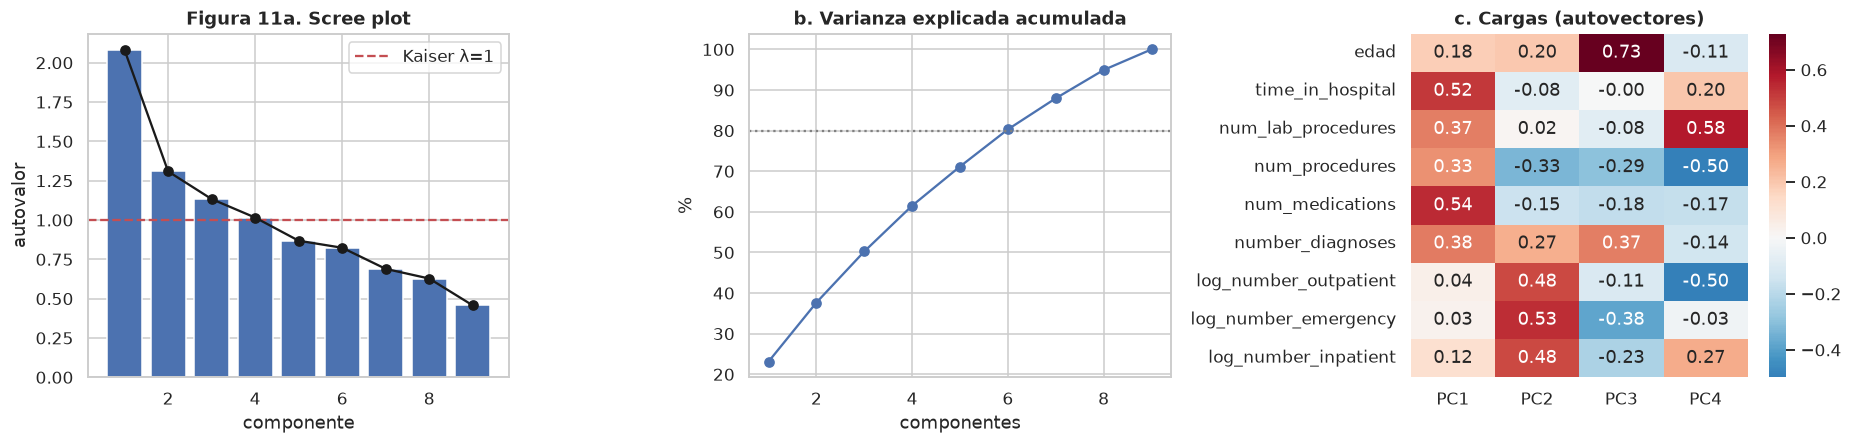

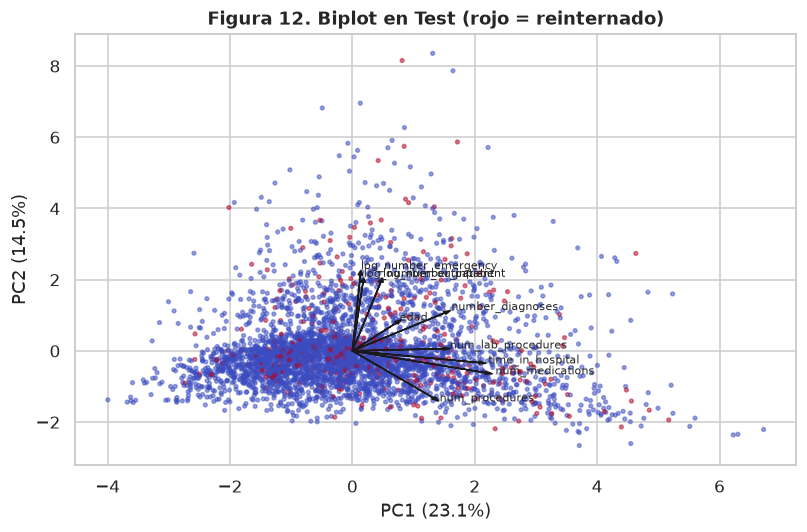

In [23]:
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

pca_pipe = Pipeline([("scaler", StandardScaler()), ("pca", PCA(random_state=SEED))]).fit(Xtr_all[PCA_VARS])
pcs_tr, pcs_te = pca_pipe.transform(Xtr_all[PCA_VARS]), pca_pipe.transform(Xte_all[PCA_VARS])
lam = pca_pipe.named_steps["pca"].explained_variance_
ratio = pca_pipe.named_steps["pca"].explained_variance_ratio_
print("Autovalores λ_k:", np.round(lam, 3))
print(f"Kaiser (λ>1): {int((lam > 1).sum())} componentes | varianza acumulada: {100 * ratio[:(lam > 1).sum()].sum():.1f}%")
print(f"Control de fuga — media de PC1 en Train: {pcs_tr[:, 0].mean():.2e} (≈0 por construcción) | "
      f"en Test: {pcs_te[:, 0].mean():.4f} (≠0: proyección ciega)")

fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
k = np.arange(1, len(lam) + 1)
axes[0].bar(k, lam, color="#4C72B0")
axes[0].axhline(1, ls="--", color="r", label="Kaiser λ=1")
axes[0].plot(k, lam, "ko-")
axes[0].set(title=f"Figura {next(FIG)}a. Scree plot", xlabel="componente", ylabel="autovalor")
axes[0].legend()
axes[1].plot(k, 100 * np.cumsum(ratio), "o-")
axes[1].axhline(80, ls=":", color="gray")
axes[1].set(title="b. Varianza explicada acumulada", xlabel="componentes", ylabel="%")
load = pd.DataFrame(pca_pipe.named_steps["pca"].components_[:4].T, index=PCA_VARS,
                    columns=[f"PC{i}" for i in range(1, 5)])
sns.heatmap(load, annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=axes[2])
axes[2].set_title("c. Cargas (autovectores)")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(7.5, 5))
sel = np.random.default_rng(SEED).choice(len(pcs_te), 4000, replace=False)
ax.scatter(pcs_te[sel, 0], pcs_te[sel, 1], c=yte_all.to_numpy()[sel], cmap="coolwarm", s=6, alpha=.5)
for v, (x, y) in zip(PCA_VARS, load[["PC1", "PC2"]].to_numpy()):
    ax.arrow(0, 0, 4 * x, 4 * y, color="k", head_width=.08)
    ax.text(4.3 * x, 4.3 * y, v, fontsize=7)
ax.set(title=f"Figura {next(FIG)}. Biplot en Test (rojo = reinternado)", xlabel=f"PC1 ({100 * ratio[0]:.1f}%)",
       ylabel=f"PC2 ({100 * ratio[1]:.1f}%)")
plt.tight_layout()
plt.show()

**Retención.** El criterio de Kaiser retiene **4 componentes** (λ₄ = 1,015, en el límite) que explican 61,5% de la varianza; el codo del scree está en la 2ª. Las 9 variables son poco redundantes (correlaciones bajas), por eso el PCA **no comprime mucho**: hacen falta 6 componentes para el 80%.

**Interpretación de negocio de las cargas:**
* **PC1 (23%) — "intensidad de la internación índice":** cargas de medicamentos (0,54), días (0,52), diagnósticos, análisis y procedimientos. Pacientes con PC1 alto consumen muchos recursos *durante* la internación.
* **PC2 (14,5%) — "uso previo del sistema de salud":** guardia (0,53), consultas ambulatorias e internaciones del año previo (0,48), casi ortogonal a la intensidad actual.
* PC3 es esencialmente **edad** (0,73) con comorbilidad; PC4 contrapone análisis vs. procedimientos.
* En Test, los reinternados tienen en promedio PC1 = +0,30 y PC2 = +0,27 frente a ≈ 0 en los no reinternados: el riesgo combina **intensidad actual** e **historia** del paciente.

Usamos el PCA para **exploración y visualización** (módulo de la app). No lo usamos como entrada de los modelos predictivos: con 9 variables poco correlacionadas, comprimir pierde información sin ganar estabilidad.

# 7. Fase 3 — Diseño del torneo predictivo

* **Target:** `readmit30` (binaria, 9%). **Predictores:** 20 variables (9 numéricas, 4 binarias, 7 categóricas), **incluido** el tratamiento: para *predecir* toda información disponible al alta es válida.
* **Partición:** Train 80% / Test 20%, **estratificada** por $Y$ (misma prevalencia de 8,97% en ambos), semilla 42. Al haber una fila por paciente no hay fuga por paciente repetido. Se complementa con un **corte cronológico** (§9.3).
* **Validación:** `StratifiedKFold(5)` dentro de Train para todo ajuste de hiperparámetros.
* **Sin fuga:** escalado y one-hot se ajustan dentro de un `Pipeline`, es decir, **dentro de cada fold**.
* **Métrica de selección:** AUC-ROC (invariante al desbalance). Se reportan además PR-AUC, Brier, log-loss y, con un umbral elegido en Train (máximo F1 en predicciones *out-of-fold*), Precision, Recall y F1.

In [24]:
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, StratifiedKFold, cross_val_predict

Xtr, Xte, ytr, yte = Xtr_all, Xte_all, ytr_all, yte_all
cv = StratifiedKFold(N_FOLDS, shuffle=True, random_state=SEED)
print(f"Train: {len(Xtr):,} ({100 * ytr.mean():.2f}% positivos) | Test: {len(Xte):,} ({100 * yte.mean():.2f}% positivos)")
resultados, probas_test, oof = {}, {}, {}

Train: 55,976 (8.97% positivos) | Test: 13,994 (8.97% positivos)


## 7.1 Familia 1 — Regresión logística regularizada

$\min_\beta -\ell(\beta) + \frac{1}{C}\left[\frac{1-\rho}{2}\|\beta\|_2^2 + \rho\|\beta\|_1\right]$ con $\rho$ = `l1_ratio` (0 = Ridge, 1 = Lasso, intermedio = ElasticNet). Búsqueda en grilla sobre $C$ y $\rho$.

param_model__l1_ratio,0.0000,0.5000,1.0000
param_model__C,,,
0.0030,0.6166,0.6064,0.6048
0.0100,0.6167,0.6133,0.6090
0.1000,0.6159,0.6164,0.6165
1.0000,0.6157,0.6159,0.6159


Mejor: {'model__C': 0.01, 'model__l1_ratio': 0.0} AUC CV = 0.6167


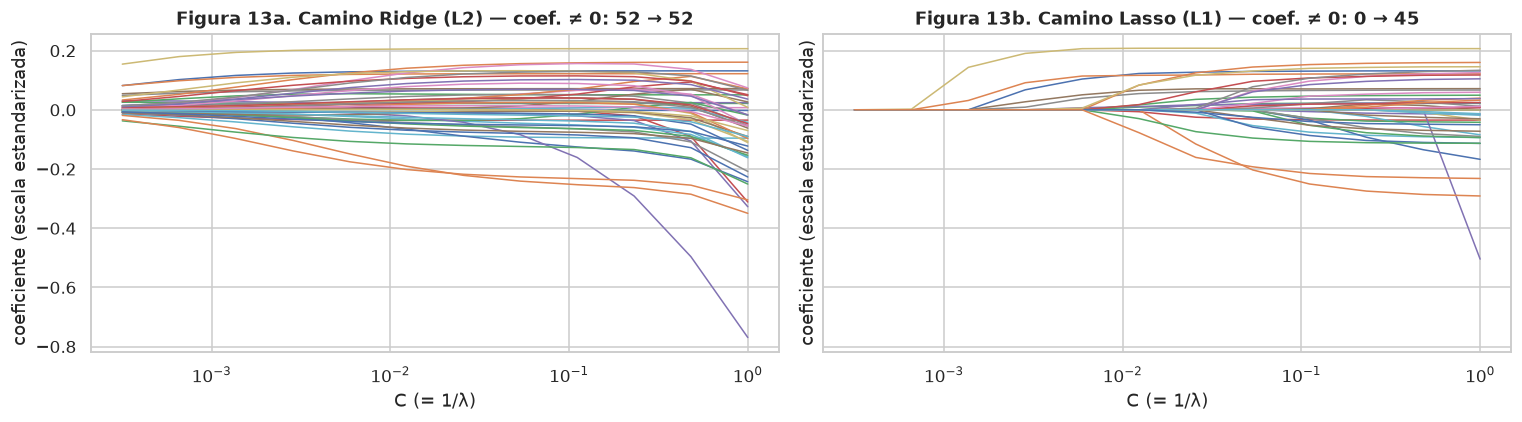

In [25]:
from sklearn.linear_model import LogisticRegression

gs_log = GridSearchCV(Mdl.make_pipe(LogisticRegression(solver="saga", max_iter=3000, tol=1e-3)),
                      {"model__C": [0.003, 0.01, 0.1, 1.0], "model__l1_ratio": [0.0, 0.5, 1.0]},
                      scoring="roc_auc", cv=cv, n_jobs=-1).fit(Xtr, ytr)
res_log = pd.DataFrame(gs_log.cv_results_)[["param_model__C", "param_model__l1_ratio", "mean_test_score", "std_test_score"]]
display(res_log.pivot(index="param_model__C", columns="param_model__l1_ratio", values="mean_test_score"))
print("Mejor:", gs_log.best_params_, f"AUC CV = {gs_log.best_score_:.4f}")
best_log = gs_log.best_estimator_

# camino de regularización: cuántos coeficientes anula L1 vs L2
Cs = np.logspace(-3.5, 0, 12)
caminos = {}
for rho in [0.0, 1.0]:
    co = []
    for c in Cs:
        mm = Mdl.make_pipe(LogisticRegression(solver="saga", C=c, l1_ratio=rho, max_iter=3000, tol=1e-3)).fit(Xtr, ytr)
        co.append(mm.named_steps["model"].coef_[0])
    caminos[rho] = np.array(co)
nombres = best_log.named_steps["pre"].get_feature_names_out()
fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
nfig = next(FIG)
for ax, rho, tit, letra in [(axes[0], 0.0, "Ridge (L2)", "a"), (axes[1], 1.0, "Lasso (L1)", "b")]:
    ax.plot(Cs, caminos[rho], lw=1)
    ax.set_xscale("log")
    nz = (np.abs(caminos[rho]) > 1e-6).sum(1)
    ax.set(title=f"Figura {nfig}{letra}. Camino {tit} — coef. ≠ 0: {nz[0]} → {nz[-1]}", xlabel="C (= 1/λ)",
           ylabel="coeficiente (escala estandarizada)")
plt.tight_layout()
plt.show()

Las diferencias de AUC entre penalizaciones son mínimas (0,615–0,617), salvo Lasso muy penalizado ($C \le 0{,}01$), que descarta variables útiles: con 56.000 filas y ~60 parámetros el sobreajuste es bajo y la regularización mejora poco. La diferencia **cualitativa** se ve en el camino: **Lasso** anula coeficientes (selección de variables: con $C \approx 10^{-3}$ sobrevive una sola variable, internaciones previas, y las demás entran de a una al relajar la penalización), mientras **Ridge** los encoge de forma continua sin llevarlos nunca a cero (52 coeficientes ≠ 0 en todo el camino). La mejor combinación por CV es Ridge con $C = 0{,}01$.

### Odds ratios con IC 95%

Para interpretar, ajustamos la logística **sin penalización** por máxima verosimilitud (Newton-Raphson) con variables en escala original: $OR_j = e^{\beta_j}$, $IC = e^{\beta_j \pm 1{,}96\,se_j}$, con $Var(\hat\beta) = (X'WX)^{-1}$.

In [26]:
Xd_tr = Mdl.logit_design(Xtr)
or_tab = Mdl.logit_odds_ratios(Xd_tr, ytr)
display(or_tab.drop(index="const").sort_values("p_value").head(15)[["OR", "OR_ci_low", "OR_ci_high", "p_value"]])

/content/TPI_HbA1c_reinternacion/src/tpi/models.py:97: RuntimeWarning: overflow encountered in exp
  "OR_ci_high": np.exp(beta + z * se),


,OR,OR_ci_low,OR_ci_high,p_value
log_number_inpatient,2.0069,1.8530,2.1736,0.0000
edad,1.0083,1.0060,1.0105,0.0000
time_in_hospital,1.0425,1.0307,1.0544,0.0000
diag_principal_Respiratorio,0.7028,0.6331,0.7801,0.0000
cobertura_Privada,0.7718,0.7059,0.8439,0.0000
log_number_emergency,1.3369,1.1939,1.4970,0.0000
especialidad_Cardiologia,0.7156,0.6174,0.8294,0.0000
number_diagnoses,1.0364,1.0185,1.0546,0.0001
cobertura_Medicare,0.8645,0.8015,0.9325,0.0002
diag_principal_Otro,0.8431,0.7678,0.9259,0.0004


* **`log_number_inpatient`:** OR ≈ 2,0 por unidad de log: pasar de 0 a 1 internación previa (+0,69 en log) multiplica las chances de reinternación por $2{,}0^{0{,}69} \approx 1{,}6$. Las visitas a guardia (OR 1,34) y cada día de internación (OR 1,04) también suman riesgo.
* Diagnóstico respiratorio (OR 0,70), cardiología (0,72) y cobertura privada (0,77) se asocian a menor riesgo.
* `diabetesMed` tiene OR 1,18: los pacientes medicados son, a igualdad del resto, de mayor riesgo (indicación por gravedad).
* ⚠️ `hba1c_medida` aparece con **OR = 0,91 (IC 0,84–0,99, p = 0,02)**, "significativo". Pero este modelo incluye días de internación y nº de análisis, que son **descendientes** del tratamiento: es exactamente la trampa post-tratamiento/colisionador que se demuestra en §11.3. Un coeficiente de un modelo predictivo **no** es un efecto causal.

## 7.2 Familia 2 — Naive Bayes

Supuesto: $P(X_1,\dots,X_p \mid Y) = \prod_j P(X_j \mid Y)$. Implementamos **GaussianNB** sobre las numéricas estandarizadas y **CategoricalNB** sobre todas las variables discretizadas en quintiles (mezcla de tipos).

Naive Bayes Gaussiano: AUC OOF = 0.6002
Naive Bayes Categórico: AUC OOF = 0.5902
Naive Bayes Categórico + calibración isotónica: AUC OOF = 0.5889
|r| medio dentro de Y=0: 0.111 | máx: 0.467


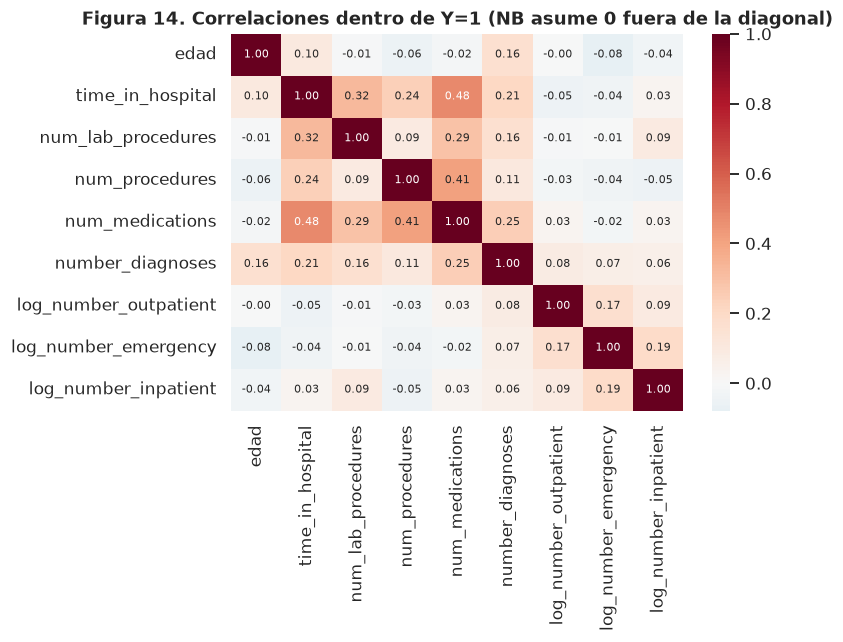

In [27]:
from sklearn.calibration import CalibratedClassifierCV
from sklearn.compose import ColumnTransformer
from sklearn.naive_bayes import CategoricalNB, GaussianNB

gnb = Pipeline([("pre", ColumnTransformer([("num", StandardScaler(), PRED_NUM)])), ("model", GaussianNB())])
cnb = Mdl.make_pipe(CategoricalNB(alpha=1.0), Mdl.preprocessor_discreto())
cnb_cal = CalibratedClassifierCV(Mdl.make_pipe(CategoricalNB(alpha=1.0), Mdl.preprocessor_discreto()),
                                 method="isotonic", cv=cv)
for nombre, mm in [("Naive Bayes Gaussiano", gnb), ("Naive Bayes Categórico", cnb),
                   ("Naive Bayes Categórico + calibración isotónica", cnb_cal)]:
    oof[nombre] = cross_val_predict(mm, Xtr, ytr, cv=cv, method="predict_proba")[:, 1]
    print(f"{nombre}: AUC OOF = {roc_auc_score(ytr, oof[nombre]):.4f}")

# violación del supuesto: correlaciones dentro de cada clase
within = {yv: Xtr.loc[ytr == yv, PRED_NUM].corr() for yv in [0, 1]}
off = ~np.eye(len(PRED_NUM), dtype=bool)
print(f"|r| medio dentro de Y=0: {within[0].abs().to_numpy()[off].mean():.3f} | máx: {within[0].abs().to_numpy()[off].max():.3f}")
fig, ax = plt.subplots(figsize=(7.5, 6))
sns.heatmap(within[1], annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax, annot_kws={"size": 7})
ax.set_title(f"Figura {next(FIG)}. Correlaciones dentro de Y=1 (NB asume 0 fuera de la diagonal)")
plt.tight_layout()
plt.show()

Las variables de intensidad están correlacionadas **dentro de cada clase** (días–medicamentos r ≈ 0,47; procedimientos–medicamentos ≈ 0,4), violando el supuesto. Efecto: NB **cuenta varias veces la misma evidencia** (si un paciente tiene muchos días, muchos medicamentos y muchos análisis, NB multiplica tres verosimilitudes que dicen lo mismo), lo que **empuja las probabilidades a los extremos** y deteriora la calibración (§9.2), aunque el *ranking* (AUC) se resiente menos. La calibración isotónica posterior corrige la escala de probabilidad sin cambiar el orden.

## 7.3 Familia 3 — Árbol CART y poda por complejidad de costo

Primero, el árbol sin restricciones para ilustrar el sobreajuste:

In [28]:
from sklearn.tree import DecisionTreeClassifier, plot_tree

arbol_full = Mdl.make_pipe(DecisionTreeClassifier(random_state=SEED)).fit(Xtr, ytr)
auc_tr_full = roc_auc_score(ytr, arbol_full.predict_proba(Xtr)[:, 1])
auc_te_full = roc_auc_score(yte, arbol_full.predict_proba(Xte)[:, 1])
print(f"Árbol sin poda: {arbol_full[-1].get_n_leaves():,} hojas, profundidad {arbol_full[-1].get_depth()} | "
      f"AUC Train = {auc_tr_full:.3f} | AUC Test = {auc_te_full:.3f}")

Árbol sin poda: 7,598 hojas, profundidad 40 | AUC Train = 1.000 | AUC Test = 0.517


**Sobreajuste severo:** 7.598 hojas y 40 niveles que memorizan el entrenamiento (AUC = 1,00) y casi no generalizan (AUC test = 0,52, apenas mejor que el azar).

**Poda:** $R_\alpha(T) = R(T) + \alpha|T|$, donde $|T|$ es el número de hojas. `cost_complexity_pruning_path` da la secuencia de $\alpha$ donde el árbol óptimo cambia; elegimos $\alpha_{opt}$ por validación cruzada de 5 pliegues.

Camino de poda: 2,003 valores de α
α_opt (máx AUC CV) = 5.44e-05 | α (regla 1-SE) = 5.44e-05


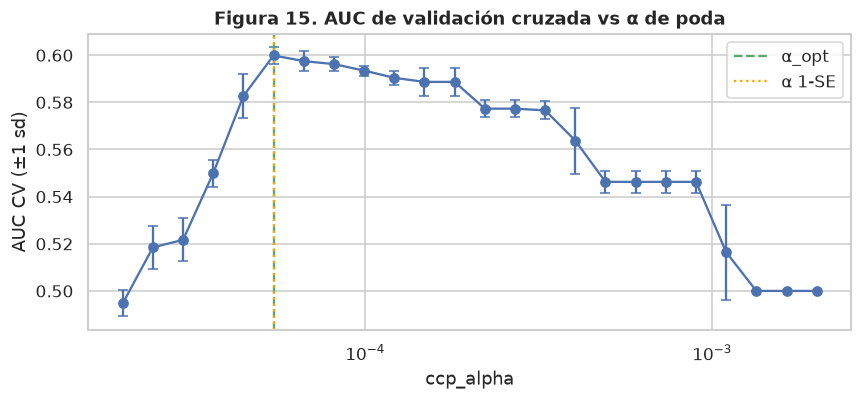

Árbol podado: 21 hojas, profundidad 9 | AUC Train = 0.606


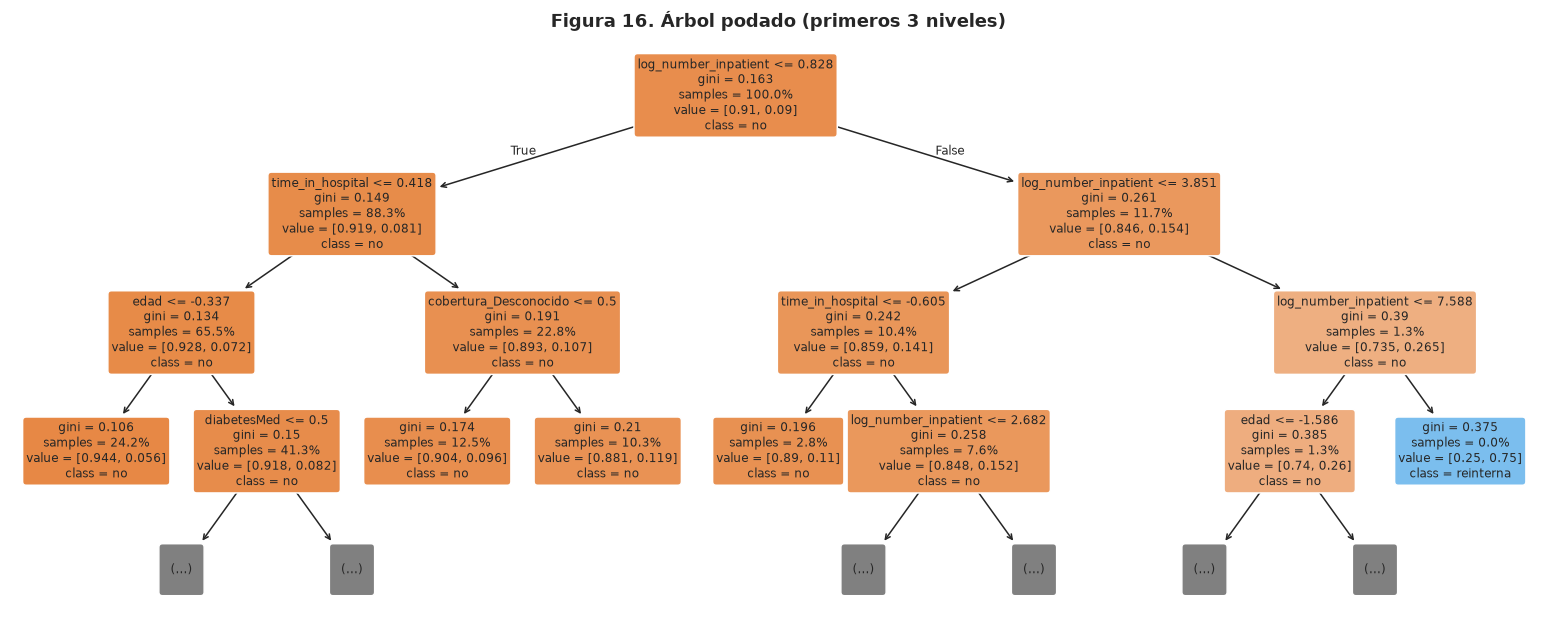

Regla del nodo raíz: log_number_inpatient <= 0.828 (en escala estandarizada)


In [29]:
from sklearn.model_selection import cross_val_score

Xtr_pre = Mdl.preprocessor().fit(Xtr).transform(Xtr)
path = DecisionTreeClassifier(random_state=SEED).cost_complexity_pruning_path(Xtr_pre, ytr)
print(f"Camino de poda: {len(path.ccp_alphas):,} valores de α")
alphas = np.unique(np.concatenate([np.geomspace(2e-5, 2e-3, 24), [0.0]]))
cv_alpha = []
for al in alphas:
    s = cross_val_score(Mdl.make_pipe(DecisionTreeClassifier(ccp_alpha=al, random_state=SEED)), Xtr, ytr,
                        cv=cv, scoring="roc_auc", n_jobs=-1)
    cv_alpha.append({"alpha": al, "auc_cv": s.mean(), "sd": s.std()})
cv_alpha = pd.DataFrame(cv_alpha)
best_i = cv_alpha.auc_cv.idxmax()
# regla de 1 error estándar: el árbol más simple cuyo AUC está a 1 SE del mejor
umbral_1se = cv_alpha.auc_cv[best_i] - cv_alpha.sd[best_i] / np.sqrt(N_FOLDS)
alpha_1se = cv_alpha.loc[cv_alpha.auc_cv >= umbral_1se, "alpha"].max()
alpha_opt = cv_alpha.alpha[best_i]
print(f"α_opt (máx AUC CV) = {alpha_opt:.2e} | α (regla 1-SE) = {alpha_1se:.2e}")

fig, ax = plt.subplots(figsize=(8, 3.8))
cc = cv_alpha[cv_alpha.alpha > 0]
ax.errorbar(cc.alpha, cc.auc_cv, yerr=cc.sd, fmt="o-", capsize=3)
ax.axvline(alpha_opt, color="g", ls="--", label="α_opt")
ax.axvline(alpha_1se, color="orange", ls=":", label="α 1-SE")
ax.set_xscale("log")
ax.set(title=f"Figura {next(FIG)}. AUC de validación cruzada vs α de poda", xlabel="ccp_alpha", ylabel="AUC CV (±1 sd)")
ax.legend()
plt.tight_layout()
plt.show()

arbol = Mdl.make_pipe(DecisionTreeClassifier(ccp_alpha=alpha_opt, random_state=SEED)).fit(Xtr, ytr)
print(f"Árbol podado: {arbol[-1].get_n_leaves()} hojas, profundidad {arbol[-1].get_depth()} | "
      f"AUC Train = {roc_auc_score(ytr, arbol.predict_proba(Xtr)[:, 1]):.3f}")
fig, ax = plt.subplots(figsize=(18, 7))
plot_tree(arbol[-1], max_depth=3, feature_names=arbol[0].get_feature_names_out(), class_names=["no", "reinterna"],
          filled=True, proportion=True, rounded=True, fontsize=8, ax=ax)
ax.set_title(f"Figura {next(FIG)}. Árbol podado (primeros 3 niveles)")
plt.show()
raiz = arbol[-1].tree_
nom_raiz = arbol[0].get_feature_names_out()[raiz.feature[0]]
print(f"Regla del nodo raíz: {nom_raiz} <= {raiz.threshold[0]:.3f} (en escala estandarizada)")

El AUC de CV crece al podar hasta $\alpha_{opt} \approx 5{,}4 \cdot 10^{-5}$ y luego cae (el árbol se vuelve demasiado simple); aquí la regla de 1 error estándar elige el mismo α. El árbol podado tiene **21 hojas** (de 7.598) y AUC de Train ≈ CV ≈ 0,60: el sobreajuste desapareció.

**Regla del nodo raíz:** la primera partición es sobre **internaciones previas** (`log_number_inpatient` estandarizado ≤ 0,83, que en escala original es $\log(1+x) \le 0{,}35$, es decir, **0 vs ≥1 internación previa**). Del lado "sin internaciones previas" la tasa de reinternación es 8,1%; del otro, 15,4% (casi el doble). Los niveles siguientes separan por visitas a guardia, edad y días de internación. Es una regla de triage simple y auditable: "**paciente con alguna internación en el último año → seguimiento reforzado**".

## 7.4 Familia 4 — Random Forest con búsqueda de hiperparámetros

In [30]:
from sklearn.ensemble import RandomForestClassifier

rs_rf = RandomizedSearchCV(
    Mdl.make_pipe(RandomForestClassifier(n_jobs=-1, random_state=SEED)),
    {"model__n_estimators": [200, 400], "model__max_depth": [6, 10, 16, None],
     "model__min_samples_split": [2, 20, 100], "model__min_samples_leaf": [1, 10, 30, 80],
     "model__max_features": ["sqrt", "log2", 0.3]},
    n_iter=20, scoring="roc_auc", cv=cv, random_state=SEED, n_jobs=1).fit(Xtr, ytr)
top_rf = (pd.DataFrame(rs_rf.cv_results_).sort_values("mean_test_score", ascending=False)
          [["params", "mean_test_score", "std_test_score", "mean_fit_time"]].head(6))
display(top_rf)
print("Mejores hiperparámetros:", rs_rf.best_params_, f"| AUC CV = {rs_rf.best_score_:.4f}")
best_rf = rs_rf.best_estimator_

,params,mean_test_score,std_test_score,mean_fit_time
4,"{'model__n_estimators': 400, 'model__min_sampl...",0.6249,0.0048,10.4936
1,"{'model__n_estimators': 400, 'model__min_sampl...",0.6248,0.0041,9.7618
2,"{'model__n_estimators': 200, 'model__min_sampl...",0.6246,0.0056,4.0428
18,"{'model__n_estimators': 400, 'model__min_sampl...",0.6237,0.0043,8.8192
12,"{'model__n_estimators': 200, 'model__min_sampl...",0.6236,0.0050,3.2266
13,"{'model__n_estimators': 400, 'model__min_sampl...",0.6234,0.0052,17.9140


Mejores hiperparámetros: {'model__n_estimators': 400, 'model__min_samples_split': 2, 'model__min_samples_leaf': 30, 'model__max_features': 'log2', 'model__max_depth': 16} | AUC CV = 0.6249


### Error Out-of-Bag vs. validación cruzada

Cada árbol se entrena con una muestra bootstrap; el ~37% de filas que quedan afuera (*out-of-bag*) sirven de validación gratuita. Graficamos la convergencia del AUC OOB al agregar árboles y la comparamos con el AUC de CV.

,árboles,AUC OOB,error OOB (1-accuracy)
0,25,0.5988,0.0897
1,50,0.6110,0.0897
2,100,0.6168,0.0897
3,150,0.6201,0.0897
4,200,0.6213,0.0897
5,300,0.6219,0.0897
6,400,0.6225,0.0897
7,600,0.6229,0.0897


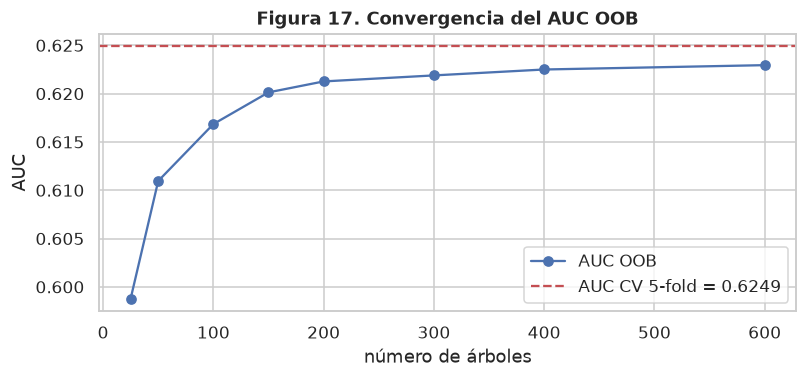

In [31]:
bp_rf = {k.replace("model__", ""): v for k, v in rs_rf.best_params_.items() if k != "model__n_estimators"}
pre_rf = Mdl.preprocessor().fit(Xtr)
Xtr_rf = pre_rf.transform(Xtr)
rf_oob = RandomForestClassifier(**bp_rf, warm_start=True, oob_score=True, n_jobs=-1, random_state=SEED)
conv = []
for n_t in [25, 50, 100, 150, 200, 300, 400, 600]:
    rf_oob.set_params(n_estimators=n_t).fit(Xtr_rf, ytr)
    conv.append({"árboles": n_t, "AUC OOB": roc_auc_score(ytr, rf_oob.oob_decision_function_[:, 1]),
                 "error OOB (1-accuracy)": 1 - rf_oob.oob_score_})
conv = pd.DataFrame(conv)
display(conv)
fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.plot(conv["árboles"], conv["AUC OOB"], "o-", label="AUC OOB")
ax.axhline(rs_rf.best_score_, color="r", ls="--", label=f"AUC CV 5-fold = {rs_rf.best_score_:.4f}")
ax.set(title=f"Figura {next(FIG)}. Convergencia del AUC OOB", xlabel="número de árboles", ylabel="AUC")
ax.legend()
plt.tight_layout()
plt.show()

El AUC OOB se estabiliza a partir de ~200 árboles (0,621 → 0,623 entre 200 y 600) y converge al AUC de validación cruzada (0,625; diferencia en el tercer decimal): ambos estiman lo mismo — el error de generalización — y confirman que más árboles no mejoran. El *error* OOB por *accuracy* (~9%) es engañoso: equivale a predecir siempre "no reinterna".

# 8. Evaluación final en Test

Elegimos el umbral de clasificación **en Train** con predicciones *out-of-fold* (máximo F1) y recién después tocamos el Test.

In [32]:
modelos = {"Logística regularizada": best_log, "Naive Bayes Gaussiano": gnb, "Naive Bayes Categórico": cnb,
           "Naive Bayes Categórico + calibración isotónica": cnb_cal, "Árbol CART podado": arbol,
           "Random Forest": best_rf}
for nombre, mm in modelos.items():
    if nombre not in oof:
        oof[nombre] = cross_val_predict(mm, Xtr, ytr, cv=cv, method="predict_proba", n_jobs=-1)[:, 1]
    thr = Mdl.best_threshold_f1(ytr, oof[nombre])
    mm.fit(Xtr, ytr)
    probas_test[nombre] = mm.predict_proba(Xte)[:, 1]
    resultados[nombre] = Mdl.evaluate(yte, probas_test[nombre], thr)
    lo, hi = Mdl.bootstrap_auc(yte, probas_test[nombre], n_boot=300)
    resultados[nombre].update({"AUC IC95% inf": lo, "AUC IC95% sup": hi,
                               "ECE": Mdl.expected_calibration_error(yte, probas_test[nombre])})
probas_test["Línea base (tasa media)"] = np.full(len(yte), ytr.mean())
resultados["Línea base (tasa media)"] = Mdl.evaluate(yte, probas_test["Línea base (tasa media)"], 0.5)
tabla_test = pd.DataFrame(resultados).T
display(tabla_test[["AUC-ROC", "AUC IC95% inf", "AUC IC95% sup", "PR-AUC", "Brier", "LogLoss", "ECE", "Precision",
                    "Recall", "F1", "F1-macro", "F1-ponderado", "umbral"]])

,AUC-ROC,AUC IC95% inf,AUC IC95% sup,PR-AUC,Brier,LogLoss,ECE,Precision,Recall,F1,F1-macro,F1-ponderado,umbral
Logística regularizada,0.6143,0.5988,0.6310,0.1411,0.0803,0.2945,0.0063,0.1217,0.5793,0.2011,0.4614,0.6750,0.0873
Naive Bayes Gaussiano,0.5938,0.5783,0.6107,0.1333,0.1093,0.4306,0.0798,0.1155,0.4462,0.1835,0.4779,0.7195,0.0652
Naive Bayes Categórico,0.5846,0.5693,0.5997,0.1147,0.0821,0.3030,0.0228,0.1124,0.5363,0.1858,0.4507,0.6681,0.0957
Naive Bayes Categórico + calibración isotónica,0.5857,0.5710,0.6009,0.1154,0.0811,0.2985,0.0048,0.1099,0.5888,0.1853,0.4303,0.6313,0.0904
Árbol CART podado,0.5912,0.5773,0.6082,0.1248,0.0808,0.2972,0.0129,0.1129,0.5657,0.1883,0.4444,0.6546,0.0860
Random Forest,0.6187,0.6036,0.6352,0.1425,0.0803,0.2945,0.0095,0.1368,0.3984,0.2037,0.5172,0.7744,0.1049
Línea base (tasa media),0.5000,NaN,NaN,0.0897,0.0816,0.3018,NaN,0.0000,0.0000,0.0000,0.4765,0.8676,0.5000


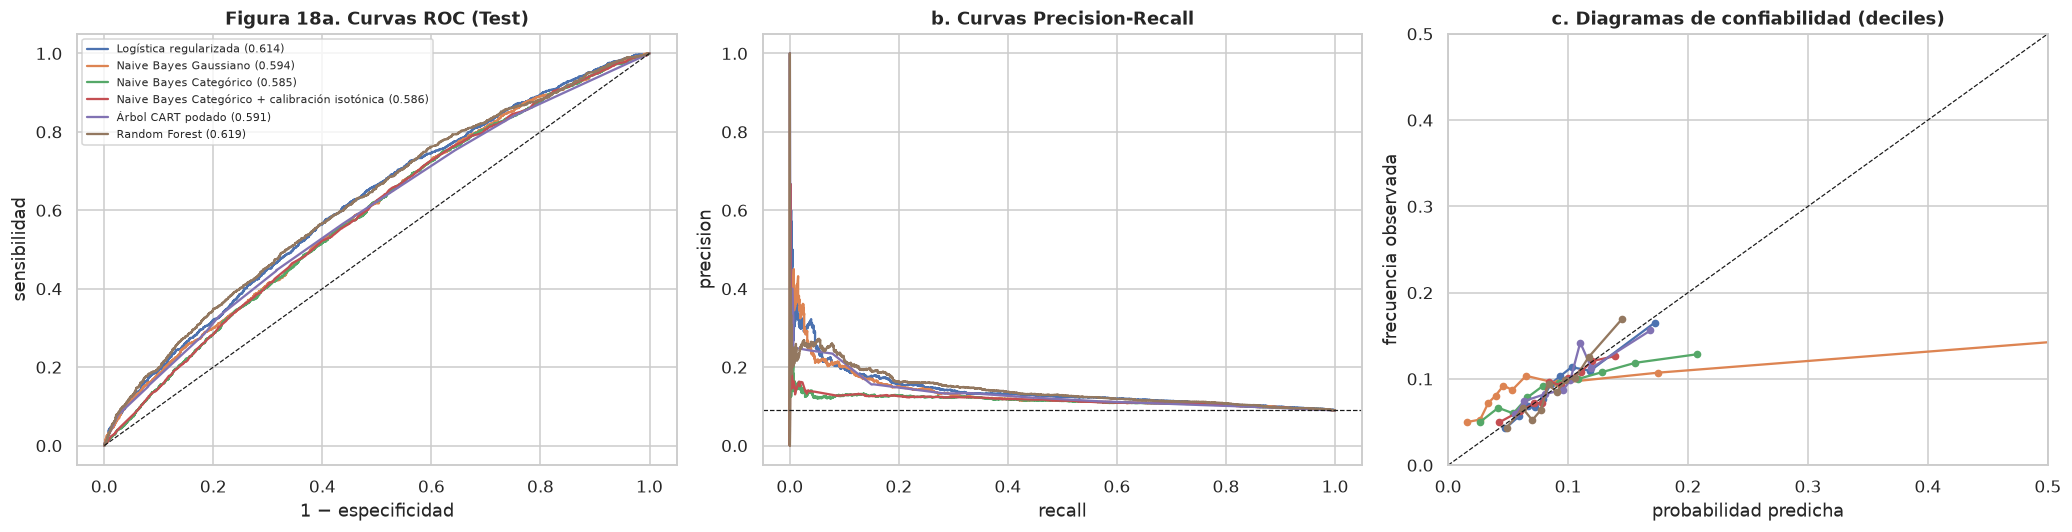

In [33]:
from sklearn.calibration import calibration_curve
from sklearn.metrics import precision_recall_curve, roc_curve

fig, axes = plt.subplots(1, 3, figsize=(19, 5))
for nombre, p in probas_test.items():
    if nombre.startswith("Línea"):
        continue
    fpr, tpr, _ = roc_curve(yte, p)
    axes[0].plot(fpr, tpr, label=f"{nombre} ({roc_auc_score(yte, p):.3f})")
    pr, rc, _ = precision_recall_curve(yte, p)
    axes[1].plot(rc, pr, label=nombre)
    pt, pp = calibration_curve(yte, p, n_bins=10, strategy="quantile")
    axes[2].plot(pp, pt, "o-", ms=4, label=nombre)
axes[0].plot([0, 1], [0, 1], "k--", lw=.8)
axes[0].set(title=f"Figura {next(FIG)}a. Curvas ROC (Test)", xlabel="1 − especificidad", ylabel="sensibilidad")
axes[0].legend(fontsize=7)
axes[1].axhline(yte.mean(), color="k", ls="--", lw=.8, label="prevalencia")
axes[1].set(title="b. Curvas Precision-Recall", xlabel="recall", ylabel="precision")
axes[2].plot([0, .5], [0, .5], "k--", lw=.8)
axes[2].set(title="c. Diagramas de confiabilidad (deciles)", xlabel="probabilidad predicha", ylabel="frecuencia observada",
            xlim=(0, .5), ylim=(0, .5))
plt.tight_layout()
plt.show()

**Resultado del torneo.**

* **Random Forest** (AUC 0,619, IC 0,604–0,635) y **Logística regularizada** (0,614, IC 0,599–0,631) quedan empatados en discriminación: sus IC bootstrap se solapan casi por completo. El RF no le gana a un modelo lineal: la señal es mayormente aditiva y débil.
* **Naive Bayes** discrimina peor (AUC 0,585–0,594) y el **Gaussiano está mal calibrado**: ECE = 0,080 (diez veces el de la logística) y el peor Brier (0,109, peor incluso que la línea base): sobreestima el riesgo en los deciles altos, como predijo la teoría de §7.2. El Categórico está mejor calibrado (ECE 0,023) y la **calibración isotónica** lo lleva a 0,005 sin cambiar su AUC.
* El **árbol podado** (AUC 0,591) es el más simple e interpretable, con discriminación similar a NB.
* El Brier de todos apenas mejora a la línea base: **la reinternación a 30 días es intrínsecamente difícil de predecir** con datos administrativos (depende de adherencia, contexto social, cuidados post-alta, que no están en la base). Estudios publicados con este dataset reportan AUC de ~0,6–0,7, consistente con nuestro resultado.
* **Uso recomendado:** no como clasificador sí/no (F1 ≈ 0,20 con el umbral óptimo), sino para **ordenar** pacientes por riesgo: el decil superior de riesgo del RF concentra una tasa de reinternación 1,9 veces la media (ver §8.2).

**Modelo para producción:** Random Forest (mejor AUC puntual, mejor F1-macro y calibración adecuada: ECE ≈ 0,01).

## 8.1 Convergencia y estabilidad: curva de aprendizaje

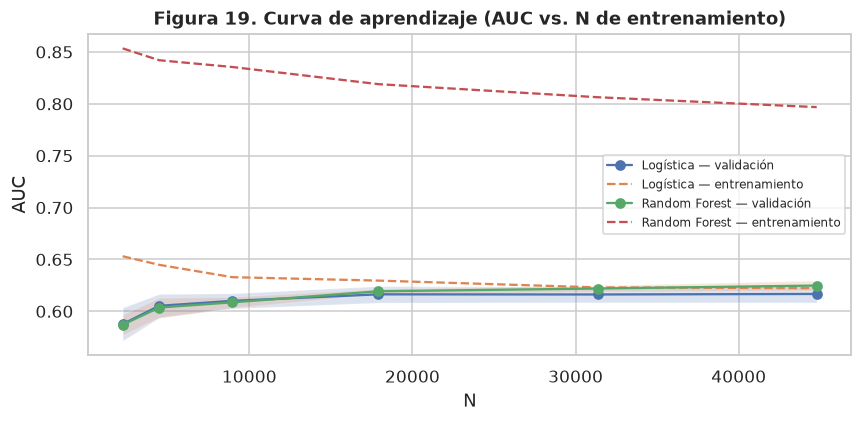

In [34]:
from sklearn.model_selection import learning_curve

lc = {}
for nombre, mm in [("Logística", best_log), ("Random Forest", best_rf)]:
    sizes, tr_s, va_s = learning_curve(mm, Xtr, ytr, cv=cv, scoring="roc_auc", n_jobs=-1,
                                       train_sizes=[0.05, 0.1, 0.2, 0.4, 0.7, 1.0], random_state=SEED, shuffle=True)
    lc[nombre] = (sizes, tr_s.mean(1), va_s.mean(1), va_s.std(1))
fig, ax = plt.subplots(figsize=(8, 4))
for nombre, (sz, trm, vam, vas) in lc.items():
    ax.plot(sz, vam, "o-", label=f"{nombre} — validación")
    ax.fill_between(sz, vam - vas, vam + vas, alpha=.2)
    ax.plot(sz, trm, "--", label=f"{nombre} — entrenamiento")
ax.set(title=f"Figura {next(FIG)}. Curva de aprendizaje (AUC vs. N de entrenamiento)", xlabel="N", ylabel="AUC")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

El AUC de validación crece hasta ~18.000 filas y luego se **aplana** (0,62). En la logística la brecha entrenamiento–validación prácticamente se cierra (sesgo, no varianza); el RF conserva una brecha (0,80 vs 0,62) pero su validación tampoco mejora con más datos. Conclusión: **más datos del mismo tipo no van a mejorar el modelo**; haría falta información nueva (variables sociales, resultados de laboratorio). La dispersión entre folds es de ±0,005: la estimación es numéricamente estable.

## 8.2 Sensibilidad: corte cronológico y utilidad por deciles

In [35]:
orden = df.loc[Xtr.index.union(Xte.index)].sort_values("encounter_id")
corte = int(0.8 * len(orden))
X_old, X_new = orden.iloc[:corte][Mdl.FEATURES], orden.iloc[corte:][Mdl.FEATURES]
y_old, y_new = orden.iloc[:corte]["readmit30"], orden.iloc[corte:]["readmit30"]
rf_t = Mdl.make_pipe(RandomForestClassifier(**{k.replace("model__", ""): v for k, v in rs_rf.best_params_.items()},
                                            n_jobs=-1, random_state=SEED)).fit(X_old, y_old)
print(f"AUC partición aleatoria = {resultados['Random Forest']['AUC-ROC']:.4f} | "
      f"AUC corte cronológico (entrena 80% más antiguo, evalúa 20% más reciente) = "
      f"{roc_auc_score(y_new, rf_t.predict_proba(X_new)[:, 1]):.4f}")

dec = pd.DataFrame({"y": yte.to_numpy(), "p": probas_test["Random Forest"]})
dec["decil"] = pd.qcut(dec.p.rank(method="first"), 10, labels=range(1, 11))
lift = dec.groupby("decil", observed=True).agg(prob_media=("p", "mean"), tasa_real=("y", "mean"), n=("y", "size"))
lift["lift"] = lift.tasa_real / yte.mean()
display(lift)

AUC partición aleatoria = 0.6187 | AUC corte cronológico (entrena 80% más antiguo, evalúa 20% más reciente) = 0.5998


,prob_media,tasa_real,n,lift
decil,,,,
1,0.0487,0.0436,1400,0.4858
2,0.0622,0.0658,1399,0.7333
3,0.0701,0.0522,1399,0.5818
4,0.0771,0.0636,1400,0.7089
5,0.0838,0.0936,1399,1.0441
6,0.0905,0.0843,1399,0.9405
7,0.0975,0.0986,1400,1.0991
8,0.1059,0.1008,1399,1.1238
9,0.1170,0.1251,1399,1.3948


* El **corte cronológico** da un AUC algo menor (0,600 vs 0,619): hay un *drift* temporal leve. En producción el modelo debería reentrenarse periódicamente y monitorearse; la partición aleatoria es algo optimista.
* **Lift:** el decil de mayor riesgo tiene una tasa real de reinternación de 16,9% (1,9 veces la media); el de menor riesgo, 4,4% (la mitad). Si el hospital puede hacer seguimiento telefónico a 10% de los pacientes, el modelo duplica la "puntería" respecto de elegir al azar.

# 9. Explicabilidad: MDI vs. importancia por permutación

,"MDI (Gini, train)","Permutación (ΔAUC, test)",n valores distintos,rank MDI,rank Perm
log_number_inpatient,0.1106,0.0290,13,1,1
cobertura,0.0552,0.0124,5,8,2
edad,0.0674,0.0110,10,6,3
diag_principal,0.0733,0.0102,9,5,4
time_in_hospital,0.0948,0.0091,14,4,5
number_diagnoses,0.0544,0.0052,16,9,6
num_medications,0.0976,0.0026,74,3,7
diabetesMed,0.0153,0.0023,2,19,8
num_procedures,0.0444,0.0022,7,10,9
num_lab_procedures,0.1100,0.0012,115,2,10


Ruido puro → rank MDI = 1 de 21 (MDI = 0.107) | ΔAUC por permutación = -0.0005


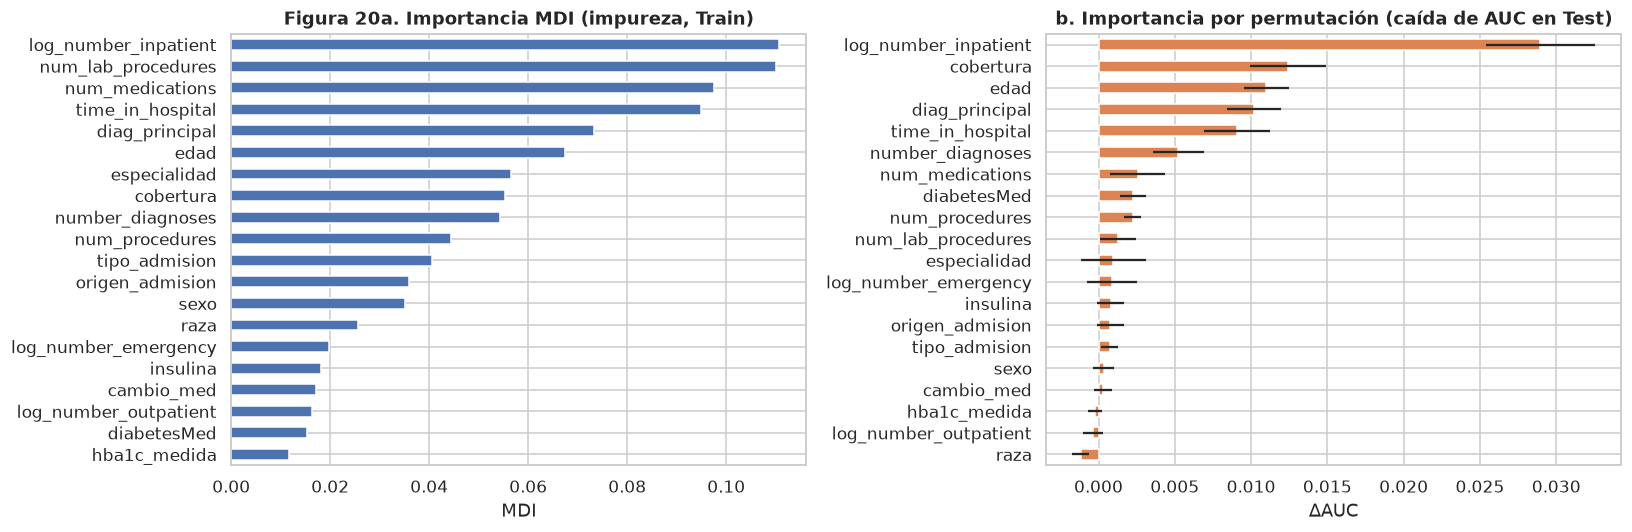

In [36]:
from sklearn.inspection import permutation_importance

mdi = Mdl.mdi_por_variable(best_rf)
perm = permutation_importance(best_rf, Xte, yte, scoring="roc_auc", n_repeats=5, random_state=SEED, n_jobs=-1)
perm_s = pd.Series(perm.importances_mean, index=Xte.columns)
imp = pd.DataFrame({"MDI (Gini, train)": mdi, "Permutación (ΔAUC, test)": perm_s,
                    "n valores distintos": Xtr.nunique()}).sort_values("Permutación (ΔAUC, test)", ascending=False)
imp["rank MDI"] = imp["MDI (Gini, train)"].rank(ascending=False).astype(int)
imp["rank Perm"] = imp["Permutación (ΔAUC, test)"].rank(ascending=False).astype(int)
display(imp)

# Experimento: variable de ruido puro de alta cardinalidad
Xtr_n = Xtr.assign(ruido_continuo=np.random.default_rng(SEED).normal(size=len(Xtr)))
Xte_n = Xte.assign(ruido_continuo=np.random.default_rng(SEED + 1).normal(size=len(Xte)))
pre_n = ColumnTransformer([("num", StandardScaler(), PRED_NUM + ["ruido_continuo"]),
                           ("bin", "passthrough", Mdl.PRED_BIN),
                           ("cat", Mdl.OneHotEncoder(handle_unknown="ignore", sparse_output=False), Mdl.PRED_CAT)],
                          verbose_feature_names_out=False)
rf_n = Pipeline([("pre", pre_n), ("model", RandomForestClassifier(**{k.replace("model__", ""): v for k, v in
                                                                      rs_rf.best_params_.items()}, n_jobs=-1,
                                                                   random_state=SEED))]).fit(Xtr_n, ytr)
mdi_n = Mdl.mdi_por_variable(rf_n)
perm_n = permutation_importance(rf_n, Xte_n, yte, scoring="roc_auc", n_repeats=5, random_state=SEED, n_jobs=-1)
perm_n = pd.Series(perm_n.importances_mean, index=Xte_n.columns)
print(f"Ruido puro → rank MDI = {int(mdi_n.rank(ascending=False)['ruido_continuo'])} de {len(mdi_n)} "
      f"(MDI = {mdi_n['ruido_continuo']:.3f}) | ΔAUC por permutación = {perm_n['ruido_continuo']:+.4f}")

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
imp["MDI (Gini, train)"].sort_values().plot.barh(ax=axes[0], color="#4C72B0")
axes[0].set(title=f"Figura {next(FIG)}a. Importancia MDI (impureza, Train)", xlabel="MDI")
imp["Permutación (ΔAUC, test)"].sort_values().plot.barh(ax=axes[1], color="#DD8452",
                                                       xerr=pd.Series(perm.importances_std, index=Xte.columns)[imp.index].sort_index())
axes[1].set(title="b. Importancia por permutación (caída de AUC en Test)", xlabel="ΔAUC")
plt.tight_layout()
plt.show()

**El dilema.** La importancia **MDI** (suma de reducciones de Gini en Train) favorece sistemáticamente a las variables **continuas de alta cardinalidad**: una variable con 100 valores distintos ofrece ~100 puntos de corte posibles; una dummy, sólo 1. Por puro azar, algún corte de la continua reducirá la impureza en el entrenamiento, y esa reducción se acumula en todos los árboles aunque no generalice. Por eso `num_lab_procedures` (115 valores distintos) es la **2ª** variable por MDI pero apenas la **10ª** por permutación, y `num_medications` (74 valores) pasa del 3er al 7º lugar.

El experimento lo demuestra de forma contundente: una columna de **ruido gaussiano puro** queda **1ª de 21 en MDI** (MDI = 0,107), mientras que su importancia por permutación en Test es ≈ 0 (ΔAUC = −0,0005).

La **permutación en Test** mide cuánto cae el AUC al romper la relación de una variable con $Y$ **en datos no vistos**: un corte espurio aprendido en Train no ayuda en Test, así que su importancia por permutación es ~0. Por eso neutraliza el sesgo. Según permutación, el ranking honesto es: **internaciones previas** (ΔAUC = 0,029) ≫ cobertura, edad, diagnóstico principal y días de internación (≈ 0,01 cada una). La medición de HbA1c tiene importancia ≈ 0.

Limitación de la permutación: con variables correlacionadas, permutar una deja a su "gemela" cubriendo la información, y ambas aparecen menos importantes de lo que son en conjunto.

# 10. Fase 4 — Inferencia causal: formalización

## 10.1 Pregunta y estimando

> **Si el hospital adopta la política "medir HbA1c a todo paciente diabético internado", ¿cuánto cambia la probabilidad de reinternación a 30 días?**

$$ATE = E[Y(1) - Y(0)] = E[Y \mid do(T=1)] - E[Y \mid do(T=0)], \qquad CATE: \tau(x) = E[Y(1)-Y(0) \mid X=x]$$

en **puntos porcentuales** (pp). $Y(t)$ es el resultado potencial bajo el tratamiento $t$.

## 10.2 DAG estructural

Supuestos de dominio (cada arco se justifica en la Entrada 4 de `BITACORA.md`):

* **Confusores $Z$** (conocidos **al ingreso**): edad, sexo, raza, tipo y origen de admisión, especialidad, cobertura, diagnóstico principal, nº de diagnósticos, internaciones/guardias/consultas del año previo. Afectan la decisión de medir **y** el riesgo de reinternación.
* **Mediador $M$** = cambio de medicación: medir HbA1c revela mal control → se ajusta el tratamiento → cambia el riesgo.
* **Colisionador $C$** = nº de análisis: el test suma análisis ($T \to C$) y los pacientes graves tienen más análisis ($U \to C$), y la gravedad $U$ (no observada) aumenta la reinternación.
* **Días de internación (LOS)**: el test y sus consecuencias (ajustes de insulina, interconsultas) pueden **prolongar** la estadía → $T \to LOS$; la gravedad también ($U \to LOS$). Es un **descendiente** de $T$, no un confusor.
* **Supuesto clave (no testeable):** dado $Z$, la gravedad no observada $U$ no influye en la decisión de medir. Se evalúa con análisis de sensibilidad (§11.6).

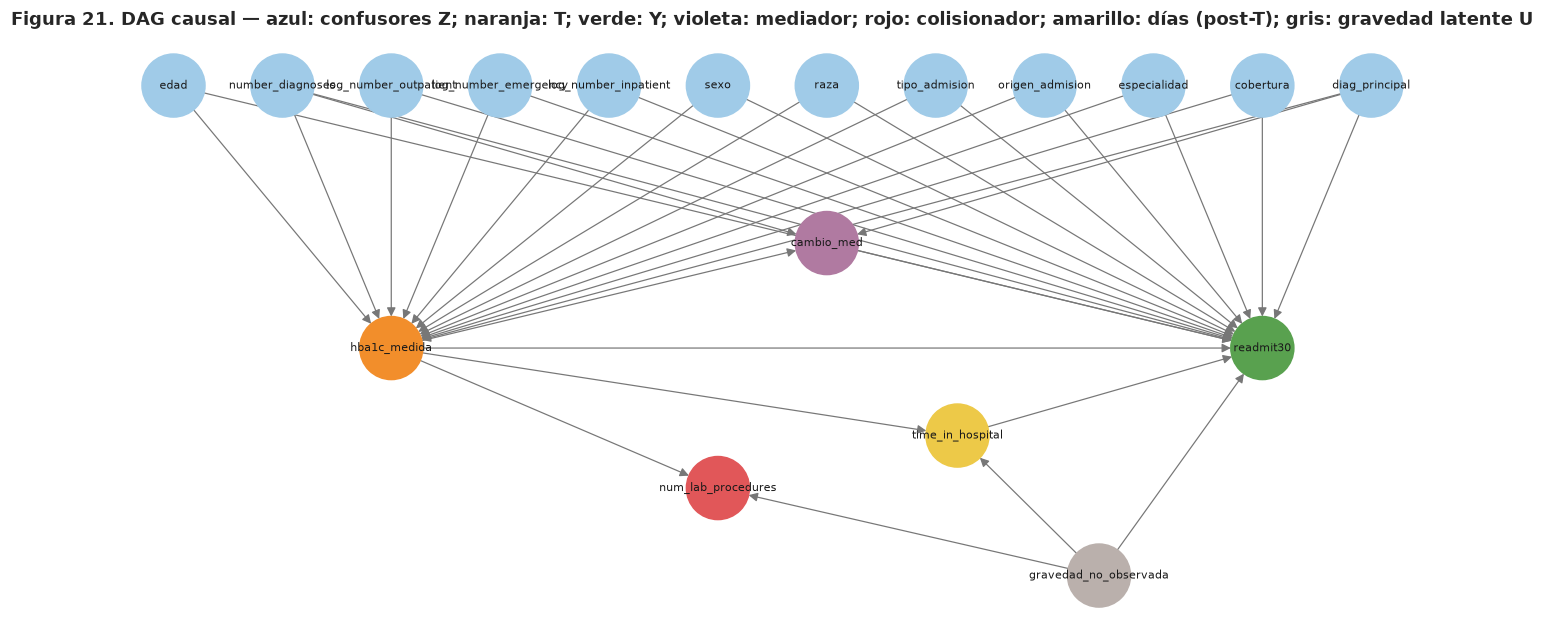

¿Es acíclico? True | nodos: 18 | aristas: 35


In [37]:
G = C.build_dag()
pos = {}
zs = Z_NUM + Z_CAT
for i, z in enumerate(zs):
    pos[z] = (i * 1.0 - len(zs) / 2, 3)
pos.update({C.T: (-4, 0), C.Y: (4, 0), C.M: (0, 1.2), C.C: (-1, -1.6), C.U: (2.5, -2.6), C.LOS: (1.2, -1.0)})
color = {C.T: "#F28E2B", C.Y: "#59A14F", C.M: "#B07AA1", C.C: "#E15759", C.U: "#BAB0AC", C.LOS: "#EDC948"}
fig, ax = plt.subplots(figsize=(17, 7))
nx.draw_networkx(G, pos, ax=ax, node_color=[color.get(n, "#A0CBE8") for n in G.nodes], node_size=1700,
                 font_size=7, arrowsize=12, edge_color="#777", width=.8)
ax.set_title(f"Figura {next(FIG)}. DAG causal — azul: confusores Z; naranja: T; verde: Y; violeta: mediador; "
             "rojo: colisionador; amarillo: días (post-T); gris: gravedad latente U")
ax.axis("off")
plt.show()
print("¿Es acíclico?", nx.is_directed_acyclic_graph(G), "| nodos:", G.number_of_nodes(), "| aristas:", G.number_of_edges())

## 10.3 Identificación: demostración del criterio backdoor

Un conjunto $Z$ satisface el **criterio backdoor** relativo a $(T, Y)$ si (i) ningún elemento de $Z$ es descendiente de $T$ y (ii) $Z$ bloquea todo camino entre $T$ e $Y$ que comienza con una flecha **hacia** $T$. Entonces:

$$P(Y \mid do(T=t)) = \sum_z P(Y \mid T=t, Z=z)\,P(Z=z)$$

**Demostración para nuestro grafo.** Todo camino backdoor tiene la forma $T \leftarrow z \rightarrow Y$ (o $T \leftarrow z \rightarrow M \rightarrow Y$) con $z \in Z$: son *forks* en $z$, que se bloquean al condicionar en $z$. No hay otras flechas que entren en $T$ (por el supuesto sobre $U$). Los caminos por $C$ ($T \to C \leftarrow U \to Y$) y por $LOS$ no son backdoor (salen de $T$); el de $C$ está **cerrado** mientras **no** condicionemos en $C$ (colisionador). Por lo tanto $Z$ es válido y suficiente.

Lo verificamos computacionalmente con d-separación (`networkx.is_d_separator`) sobre el grafo sin las aristas que salen de $T$, para varios conjuntos de ajuste candidatos:

In [38]:
caminos_bd, n_bd = C.backdoor_paths(G)
print(f"Caminos backdoor (longitud ≤ 3): {n_bd}. Ejemplos: {[' — '.join(c) for c in caminos_bd[:3]]}")
Zset = set(Z_NUM + Z_CAT)
candidatos = {"∅ (comparación naive)": set(), "Z (al ingreso)": Zset, "Z + días de internación": Zset | {C.LOS},
              "Z + mediador": Zset | {C.M}, "Z + colisionador": Zset | {C.C},
              "Z sin diagnóstico ni especialidad": Zset - {"diag_principal", "especialidad"}}
bd_tab = pd.DataFrame({k: C.backdoor_check(G, v) for k, v in candidatos.items()}).T
display(bd_tab)

Caminos backdoor (longitud ≤ 3): 14. Ejemplos: ['hba1c_medida — edad — readmit30', 'hba1c_medida — number_diagnoses — readmit30', 'hba1c_medida — number_diagnoses — cambio_med — readmit30']


,sin_descendientes_de_T,descendientes_incluidos,bloquea_backdoor,valido
∅ (comparación naive),True,[],False,False
Z (al ingreso),True,[],True,True
Z + días de internación,False,[time_in_hospital],True,False
Z + mediador,False,[cambio_med],True,False
Z + colisionador,False,[num_lab_procedures],True,False
Z sin diagnóstico ni especialidad,True,[],False,False


Sólo **Z (al ingreso)** cumple ambas condiciones. Agregar días, el mediador o el colisionador viola la condición (i); omitir confusores deja caminos abiertos (condición ii).

> **Corrección respecto de un análisis previo del equipo:** en una versión anterior se ajustaba por `time_in_hospital` como confusor. El test de HbA1c se realiza **durante** la internación y sus consecuencias pueden alargarla, por lo que los días son un descendiente de $T$. Ajustar por ellos bloquea parte del efecto y, como también dependen de la gravedad, abre un camino espurio (sesgo de colisionador/post-tratamiento). Lo cuantificamos en §11.4.

## 10.4 Positividad (solapamiento) y balance

La identificación requiere además $0 < P(T=1 \mid Z) < 1$ para todo $z$. Estimamos el *propensity score* $e(Z)$ con logística y **cross-fitting** (cada paciente es predicho por un modelo que no lo vio).

Percentiles del PS [0, 1, 50, 99, 100]%: [0.015 0.044 0.169 0.498 0.689]
AUC del modelo de propensión: 0.670


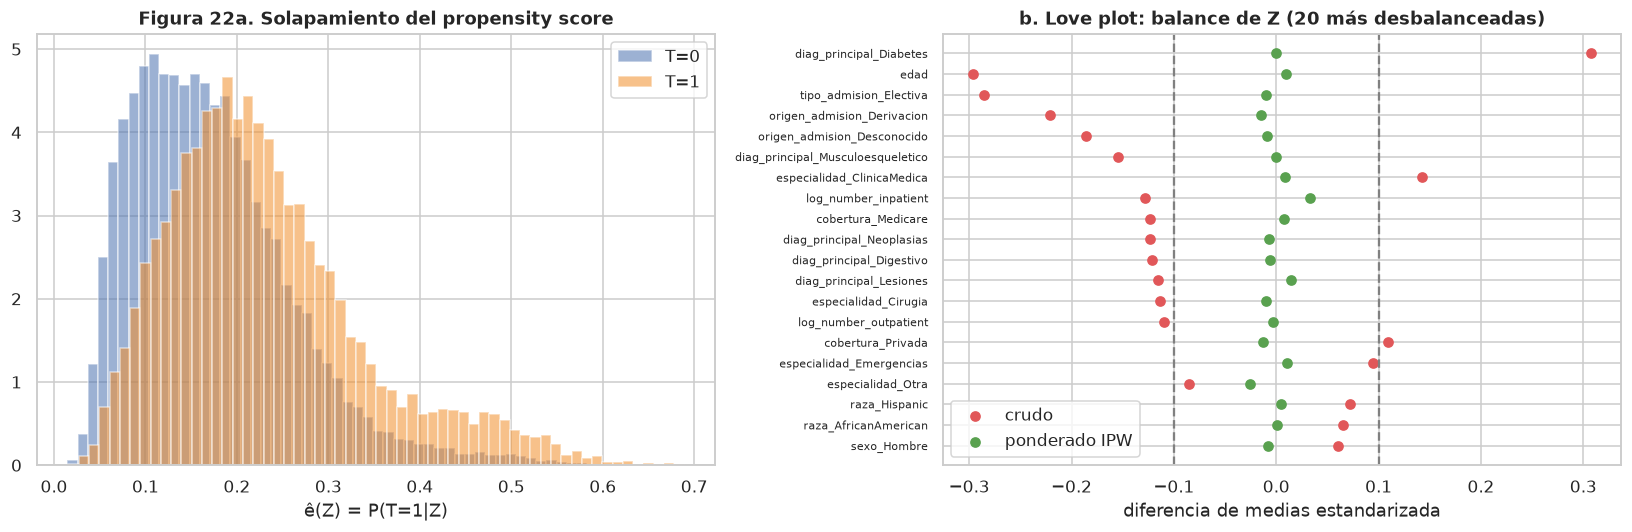

Variables con |SMD|>0,1 — antes: 15 | después de IPW: 0


In [39]:
d_c = df.copy()
e_hat = C.crossfit_propensity(d_c)
d_c["ps"] = e_hat
print("Percentiles del PS [0, 1, 50, 99, 100]%:", np.round(np.quantile(e_hat, [0, .01, .5, .99, 1]), 3))
print(f"AUC del modelo de propensión: {roc_auc_score(d_c.hba1c_medida, e_hat):.3f}")
bal = C.smd_balance(d_c, e_hat, list(C.z_matrix(d_c).columns))
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for t_, col in [(0, "#4C72B0"), (1, "#F28E2B")]:
    axes[0].hist(e_hat[d_c.hba1c_medida == t_], bins=60, alpha=.55, density=True, color=col, label=f"T={t_}")
axes[0].set(title=f"Figura {next(FIG)}a. Solapamiento del propensity score", xlabel="ê(Z) = P(T=1|Z)")
axes[0].legend()
bal_s = bal.reindex(bal.SMD_crudo.abs().sort_values().index).tail(20)
axes[1].scatter(bal_s.SMD_crudo, bal_s.variable, label="crudo", color="#E15759")
axes[1].scatter(bal_s.SMD_ponderado, bal_s.variable, label="ponderado IPW", color="#59A14F")
axes[1].axvline(.1, ls="--", color="gray")
axes[1].axvline(-.1, ls="--", color="gray")
axes[1].set(title="b. Love plot: balance de Z (20 más desbalanceadas)", xlabel="diferencia de medias estandarizada")
axes[1].tick_params(axis="y", labelsize=7)
axes[1].legend()
plt.tight_layout()
plt.show()
print(f"Variables con |SMD|>0,1 — antes: {(bal.SMD_crudo.abs() > .1).sum()} | después de IPW: {(bal.SMD_ponderado.abs() > .1).sum()}")

El PS va de ≈ 0,01 a ≈ 0,7 y las distribuciones de ambos grupos se **solapan** ampliamente: la positividad se cumple (recortamos igualmente a [0,01; 0,99] en IPW). La ponderación por propensión **elimina el desbalance** de todas las covariables (todas quedan con |SMD| < 0,1): tras ponderar, los grupos son comparables en lo observado.

# 11. Estimación del efecto causal

## 11.1 Naive vs. backdoor (implementación de referencia)

Modelo lineal de probabilidad $Y = \alpha + \tau T + \gamma'Z + \varepsilon$: con $Y$ binaria, $\tau$ es directamente un cambio de probabilidad. La varianza de una Bernoulli depende de $X$ → errores **HC3**.

In [40]:
y_np, t_np = d_c.readmit30.to_numpy(float), d_c.hba1c_medida.to_numpy(float)
naive = C.ols_effect(d_c, adjust=False)
backdoor = C.ols_effect(d_c)
ipw = 100 * C.ipw_ate(y_np, t_np, e_hat)
ipw_ci = [100 * v for v in C.ipw_bootstrap(y_np, t_np, e_hat, n_boot=300)]
ate_tab = pd.DataFrame({
    "Naive (Y ~ T)": [naive["efecto_pp"], naive["ci_low_pp"], naive["ci_high_pp"], naive["p_value"]],
    "Backdoor: regresión (HC3)": [backdoor["efecto_pp"], backdoor["ci_low_pp"], backdoor["ci_high_pp"], backdoor["p_value"]],
    "Backdoor: IPW Hájek (bootstrap)": [ipw, ipw_ci[0], ipw_ci[1], np.nan]},
    index=["efecto (pp)", "IC95% inf", "IC95% sup", "p-valor"]).T
display(ate_tab)
sesgo = naive["efecto_pp"] - backdoor["efecto_pp"]
print(f"Sesgo de confusión = naive − ajustado = {sesgo:.2f} pp "
      f"({100 * sesgo / naive['efecto_pp']:.0f}% del efecto naive se explica por confusión)")

,efecto (pp),IC95% inf,IC95% sup,p-valor
Naive (Y ~ T),-0.7087,-1.2431,-0.1743,0.0093
Backdoor: regresión (HC3),-0.1837,-0.7337,0.3662,0.5126
Backdoor: IPW Hájek (bootstrap),-0.2151,-0.8350,0.4049,NaN


Sesgo de confusión = naive − ajustado = -0.52 pp (74% del efecto naive se explica por confusión)


**El sesgo de confusión es de ≈ −0,5 pp**: casi tres cuartos del "beneficio" aparente se explica porque el test se pidió a pacientes de **menor riesgo basal** (más jóvenes, con menos internaciones previas). **Dirección:** el sesgo es negativo (exagera el beneficio), consistente con el Love plot: los tratados tienen menos factores de riesgo. Ajustado, el efecto es ≈ −0,2 pp con un IC que incluye ampliamente al 0, y coincide con IPW (≈ −0,2 pp): dos estimadores con supuestos distintos (modelo del resultado vs. modelo del tratamiento) dan lo mismo.

## 11.2 DoWhy: Model → Identify → Estimate

In [41]:
# [DoWhy]
from dowhy import CausalModel

Zm = C.z_matrix(d_c)
G_dw = nx.DiGraph()
for z in Zm.columns:
    G_dw.add_edges_from([(z, C.T), (z, C.Y)])
G_dw.add_edges_from([(C.T, C.Y), (C.T, C.M), (C.M, C.Y), (C.T, C.C)])
data_dw = pd.concat([Zm, d_c[[C.T, C.Y, C.M, C.C]]], axis=1)
data_dw[C.T] = data_dw[C.T].astype(bool)

modelo_dw = CausalModel(data=data_dw, treatment=C.T, outcome=C.Y, graph=G_dw)  # 1. Model
estimando = modelo_dw.identify_effect(proceed_when_unidentifiable=True)  # 2. Identify
print(estimando)
np.random.seed(SEED)
est_lr = modelo_dw.estimate_effect(estimando, method_name="backdoor.linear_regression")  # 3. Estimate
est_ipw = modelo_dw.estimate_effect(estimando, method_name="backdoor.propensity_score_weighting",
                                    method_params={"weighting_scheme": "ips_stabilized_weight"})
dowhy_tab = pd.DataFrame({"DoWhy ATE (pp)": [100 * est_lr.value, 100 * est_ipw.value],
                          "Referencia propia (pp)": [backdoor["efecto_pp"], ipw]},
                         index=["backdoor.linear_regression", "backdoor.propensity_score_weighting"])
display(dowhy_tab)

Estimand type: EstimandType.NONPARAMETRIC_ATE

### Estimand : 1
Estimand name: backdoor
Estimand expression:
       d                                                                       ↪
───────────────(E[readmit30|diag_principal_Respiratorio,edad,raza_Other,raza_D ↪
d[hba1c_medida]                                                                ↪

↪                                                                              ↪
↪ esconocido,log_number_outpatient,log_number_emergency,sexo_Hombre,diag_princ ↪
↪                                                                              ↪

↪                                                                              ↪
↪ ipal_Digestivo,origen_admision_Traslado,especialidad_ClinicaMedica,especiali ↪
↪                                                                              ↪

↪                                                                              ↪
↪ dad_Otra,cobertura_Particular,diag_principal_Otro,cobertura_Medicare,especia

,DoWhy ATE (pp),Referencia propia (pp)
backdoor.linear_regression,-0.1837,-0.1837
backdoor.propensity_score_weighting,-0.2315,-0.2151


El motor de identificación de DoWhy encuentra el estimando **backdoor** con el conjunto de ajuste $Z$ y la fórmula de ajuste de §10.3. La regresión lineal de DoWhy debe reproducir exactamente nuestra estimación de referencia (mismo modelo); el IPW puede diferir en décimas porque DoWhy estima el propensity con su propia logística sin cross-fitting.

## 11.3 Las trampas: mediador y colisionador

**En los datos reales:**

In [42]:
trampas = pd.DataFrame({
    "Backdoor correcto (Z)": C.ols_effect(d_c),
    "❌ Z + días de internación": C.ols_effect(d_c, extra=[C.LOS]),
    "❌ Z + mediador (cambio_med)": C.ols_effect(d_c, extra=[C.M]),
    "❌ Z + colisionador (nº análisis)": C.ols_effect(d_c, extra=[C.C]),
    "❌ Z + mediador + colisionador": C.ols_effect(d_c, extra=[C.M, C.C])}).T
display(trampas)

,efecto_pp,ci_low_pp,ci_high_pp,p_value
Backdoor correcto (Z),-0.1837,-0.7337,0.3662,0.5126
❌ Z + días de internación,-0.4337,-0.9857,0.1183,0.1236
❌ Z + mediador (cambio_med),-0.2762,-0.8282,0.2757,0.3266
❌ Z + colisionador (nº análisis),-0.5321,-1.1012,0.0369,0.0668
❌ Z + mediador + colisionador,-0.5986,-1.1688,-0.0283,0.0397


Agregar descendientes de $T$ **empuja la estimación**: de −0,18 pp a −0,28 (mediador), −0,43 (días), −0,53 (colisionador) y −0,60 pp (mediador + colisionador), y en este último caso el efecto pasa a ser "significativo" (p = 0,04). Un analista que agrega controles "porque están en la base" reportaría un efecto protector significativo que, según el DAG, es un artefacto. **Más controles no es más riguroso: hay que elegirlos con el grafo.**

Como en datos reales no conocemos la verdad, hacemos un **experimento controlado**: mantenemos los pacientes reales ($Z$ y $T$ reales, con su confusión real) y simulamos $M$, $C$, $U$ e $Y$ con un efecto causal total **conocido**.

ATE verdadero (simulado) = -2.80 pp


,efecto_pp,ci_low_pp,ci_high_pp,p_value,contiene el ATE real
Backdoor correcto,-2.9193,-3.4231,-2.4155,0.0000,True
❌ + mediador,-1.0508,-1.5821,-0.5195,0.0001,False
❌ + colisionador,-6.4131,-6.9652,-5.8610,0.0000,False
Naive,-3.4127,-3.8995,-2.9259,0.0000,False


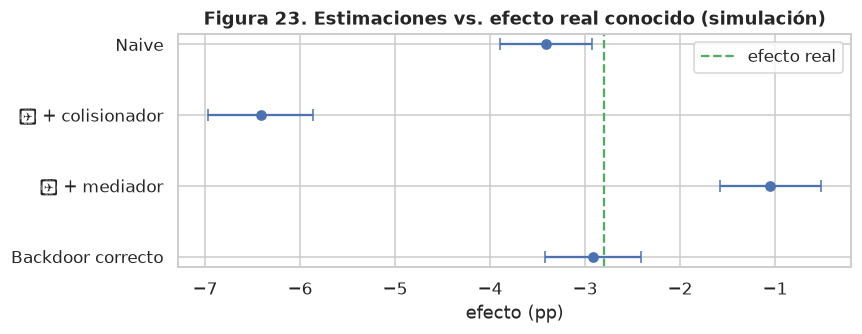

In [43]:
sim, ate_true = C.simulate_known_effect(d_c)
sim_tab = pd.DataFrame({"Backdoor correcto": C.ols_effect(sim), "❌ + mediador": C.ols_effect(sim, extra=[C.M]),
                        "❌ + colisionador": C.ols_effect(sim, extra=[C.C]),
                        "Naive": C.ols_effect(sim, adjust=False)}).T
sim_tab["contiene el ATE real"] = (sim_tab.ci_low_pp <= ate_true) & (ate_true <= sim_tab.ci_high_pp)
print(f"ATE verdadero (simulado) = {ate_true:.2f} pp")
display(sim_tab)
fig, ax = plt.subplots(figsize=(8, 3.2))
yy = np.arange(len(sim_tab))
ax.errorbar(sim_tab.efecto_pp, yy, xerr=[sim_tab.efecto_pp - sim_tab.ci_low_pp, sim_tab.ci_high_pp - sim_tab.efecto_pp],
            fmt="o", capsize=4)
ax.axvline(ate_true, color="g", ls="--", label="efecto real")
ax.set_yticks(yy, sim_tab.index)
ax.set(title=f"Figura {next(FIG)}. Estimaciones vs. efecto real conocido (simulación)", xlabel="efecto (pp)")
ax.legend()
plt.tight_layout()
plt.show()

* **Backdoor correcto:** estima −2,92 pp y su IC contiene el efecto real (−2,80 pp). El naive (−3,41) no lo contiene: la confusión real del dataset sesga.
* **+ mediador:** recupera sólo el efecto **directo** (−1,05 pp) y **subestima** el impacto total de la política en ~2/3: concluiríamos que el protocolo "casi no sirve", cuando funciona justamente **a través** del cambio de medicación.
* **+ colisionador:** **más que duplica** el efecto (−6,41 pp). Entre pacientes con el mismo número de análisis, los que **no** tuvieron el test tuvieron otros análisis → eran más graves (sesgo de Berkson): condicionar en $C$ induce una correlación espuria entre $T$ y $U$.

## 11.4 Causal ML: Double Machine Learning con EconML

El ajuste lineal supone que $Z$ afecta a $Y$ y a $T$ linealmente. **DML** (Chernozhukov et al., 2018) relaja eso con un modelo parcialmente lineal $Y = \tau(X)\,T + g(Z) + \varepsilon$, $T = m(Z) + \nu$:

1. Predice $Y$ con $Z$ (Random Forest) → $\tilde Y = Y - \hat g(Z)$.
2. Predice $T$ con $Z$ (Random Forest) → $\tilde T = T - \hat m(Z)$.
3. Regresa $\tilde Y$ sobre $\tilde T \cdot [1, X]$ (relación **ortogonal** residual), con *cross-fitting* de 5 pliegues.

La ortogonalidad (Neyman) hace que errores de primer orden en $\hat g, \hat m$ no sesguen $\hat\tau$. Modificadores de efecto $X$: diagnóstico circulatorio, admisión de emergencia, edad (centrada en 65) y log de internaciones previas.

In [44]:
X_cate = ["diag_circ", "emergencia", "edad_c", "log_number_inpatient"]  # modificadores de efecto X
print("X (heterogeneidad):", X_cate)

X (heterogeneidad): ['diag_circ', 'emergencia', 'edad_c', 'log_number_inpatient']


In [45]:
# [EconML]
from econml.dml import CausalForestDML, LinearDML
from sklearn.ensemble import RandomForestRegressor

W_cols = [c for c in Zm.columns if c not in ("edad", "log_number_inpatient")]
Y_, T_ = d_c.readmit30.to_numpy(), d_c.hba1c_medida.to_numpy()
X_, W_ = d_c[X_cate].to_numpy(float), Zm[W_cols].to_numpy(float)


def rf_y():
    return RandomForestRegressor(n_estimators=200, min_samples_leaf=50, max_features=0.3, n_jobs=-1, random_state=SEED)


def rf_t():
    return RandomForestClassifier(n_estimators=200, min_samples_leaf=50, max_features=0.3, n_jobs=-1, random_state=SEED)


ldml = LinearDML(model_y=rf_y(), model_t=rf_t(), discrete_treatment=True, cv=5, random_state=SEED)
ldml.fit(Y_, T_, X=X_, W=W_)
ate_l = ldml.ate(X_)
lo_l, hi_l = ldml.ate_interval(X_, alpha=0.05)
print(f"LinearDML: ATE = {100 * ate_l:.2f} pp | IC95% [{100 * lo_l:.2f}; {100 * hi_l:.2f}]")
display(ldml.summary(feature_names=X_cate))

cfdml = CausalForestDML(model_y=rf_y(), model_t=rf_t(), discrete_treatment=True, cv=5, n_estimators=400,
                        min_samples_leaf=200, max_depth=8, random_state=SEED)
cfdml.fit(Y_, T_, X=X_, W=W_)
ate_cf = cfdml.ate(X_)
lo_cf, hi_cf = cfdml.ate_interval(X_, alpha=0.05)
print(f"CausalForestDML: ATE = {100 * ate_cf:.2f} pp | IC95% [{100 * lo_cf:.2f}; {100 * hi_cf:.2f}]")

LinearDML: ATE = -0.26 pp | IC95% [-0.85; 0.32]


,point_estimate,stderr,zstat,pvalue,ci_lower,ci_upper
diag_circ,0.012,0.006,1.903,0.057,-0.0,0.025
emergencia,0.002,0.006,0.289,0.773,-0.01,0.013
edad_c,0.0,0.0,0.283,0.777,-0.0,0.0
log_number_inpatient,-0.029,0.014,-2.052,0.04,-0.057,-0.001
,point_estimate,stderr,zstat,pvalue,ci_lower,ci_upper
cate_intercept,-0.004,0.005,-0.88,0.379,-0.014,0.005


CausalForestDML: ATE = -0.21 pp | IC95% [-2.95; 2.52]


Para auditar EconML, replicamos el LinearDML con nuestra implementación explícita (`tpi.causal.dml_plr`, mismo algoritmo: Random Forest de *nuisance*, 5 pliegues de cross-fitting, etapa final OLS con HC3):

In [46]:
dml_ref = C.dml_plr(d_c, X_cols=X_cate, n_estimators=200)
print(f"DML de referencia — ATE (θ constante) = {dml_ref['ate_pp']:.2f} pp | IC95% "
      f"[{dml_ref['ci_low_pp']:.2f}; {dml_ref['ci_high_pp']:.2f}] | p = {dml_ref['p_value']:.3f}")
print(f"DML de referencia — ATE como promedio del CATE lineal = {dml_ref['ate_cate_pp']:.2f} pp")
cate_tab = dml_ref["cate_table"].copy()
cate_tab[["coef", "se", "ci_low", "ci_high"]] *= 100
display(cate_tab.rename(columns={"coef": "coef (pp)", "se": "se (pp)", "ci_low": "IC inf (pp)", "ci_high": "IC sup (pp)"}))

DML de referencia — ATE (θ constante) = -0.15 pp | IC95% [-0.71; 0.40] | p = 0.590
DML de referencia — ATE como promedio del CATE lineal = -0.24 pp


,coef (pp),se (pp),t,p_value,IC inf (pp),IC sup (pp)
T,-0.4132,0.4859,-0.8502,0.3952,-1.3656,0.5393
T:diag_circ,1.2552,0.6426,1.9533,0.0508,-0.0043,2.5146
T:emergencia,0.1713,0.5714,0.2998,0.7643,-0.9486,1.2912
T:edad_c,0.0042,0.0166,0.2509,0.8019,-0.0284,0.0367
T:log_number_inpatient,-2.9640,1.4148,-2.0951,0.0362,-5.7369,-0.1911


**Lectura del CATE lineal** $\tau(x) = \theta_0 + \theta_1\,\text{circ} + \theta_2\,\text{emerg} + \theta_3\,\text{edad}_c + \theta_4\,\log(1+\text{internaciones previas})$:

* $\theta_4 = -2{,}96$ pp (p = 0,036): **cuantas más internaciones previas, mayor el beneficio** de medir HbA1c (una unidad de log ≈ pasar de 0 a ~2 internaciones previas).
* $\theta_1 = +1{,}26$ pp (p = 0,051, en el límite): en **diagnóstico circulatorio** el efecto es menos favorable — el riesgo de volver lo dominan la insuficiencia cardíaca o el infarto, no la diabetes. Coincide con lo reportado por Strack et al. (2014).
* Edad y tipo de admisión no modifican el efecto.

El CausalForestDML (sin forma funcional) da un ATE parecido, pero con intervalos muy anchos: con un efecto chico y un resultado ruidoso (9% de eventos), el bosque no tiene información para estimar efectos individuales confiables. **Para decidir usamos el CATE lineal**, más estable.

## 11.5 Curvas de heterogeneidad (CATE)

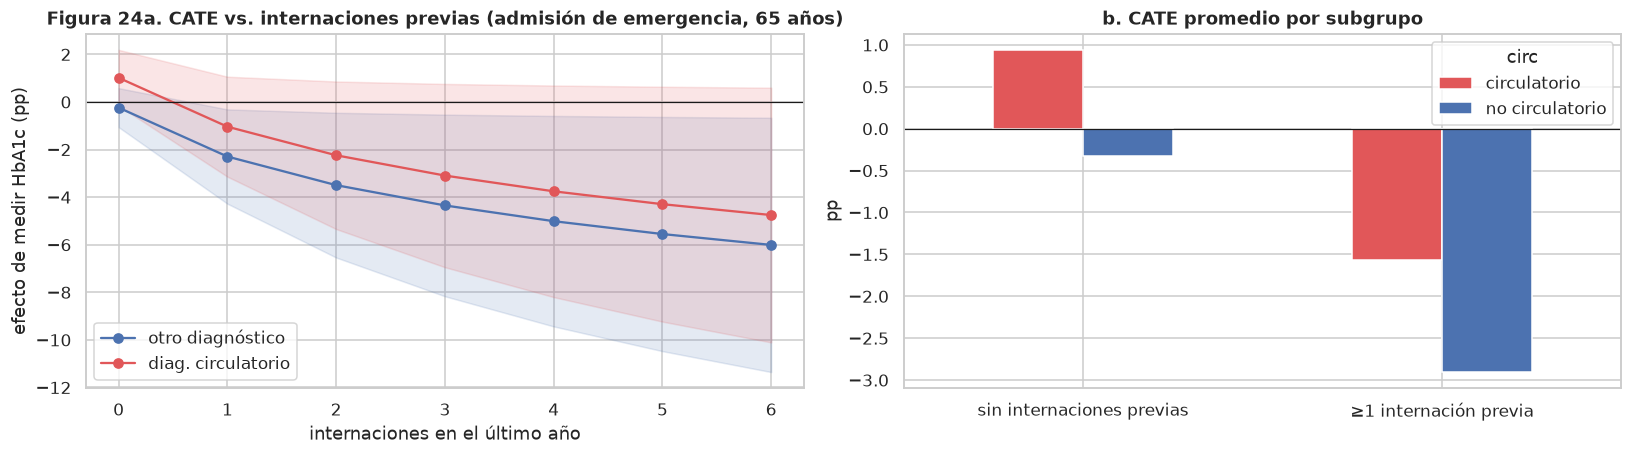

n  cate_pp
previas                   circ                           
sin internaciones previas circulatorio     18963   0.9405
                          no circulatorio  42816  -0.3294
≥1 internación previa     circulatorio      2420  -1.5660
                          no circulatorio   5771  -2.9044

In [47]:
inpat = np.arange(0, 7)
fig, axes = plt.subplots(1, 2, figsize=(15, 4.3))
for circ, col in [(0, "#4C72B0"), (1, "#E15759")]:
    Xg = np.column_stack([np.full(len(inpat), circ), np.ones(len(inpat)), np.zeros(len(inpat)), np.log1p(inpat)])
    tau, lo, hi = C.cate_predict(dml_ref["cate_coef"], dml_ref["cate_cov"], Xg)
    lab = "diag. circulatorio" if circ else "otro diagnóstico"
    axes[0].plot(inpat, 100 * tau, "o-", color=col, label=lab)
    axes[0].fill_between(inpat, 100 * lo, 100 * hi, color=col, alpha=.15)
axes[0].axhline(0, color="k", lw=.8)
axes[0].set(title=f"Figura {next(FIG)}a. CATE vs. internaciones previas (admisión de emergencia, 65 años)",
            xlabel="internaciones en el último año", ylabel="efecto de medir HbA1c (pp)")
axes[0].legend()
d_c["cate"] = dml_ref["cate"]
seg = d_c.assign(previas=np.where(d_c.number_inpatient > 0, "≥1 internación previa", "sin internaciones previas"),
                 circ=np.where(d_c.diag_circ == 1, "circulatorio", "no circulatorio"))
(seg.groupby(["previas", "circ"]).cate.mean() * 100).unstack().plot.bar(ax=axes[1], color=["#E15759", "#4C72B0"])
axes[1].axhline(0, color="k", lw=.8)
axes[1].set(title="b. CATE promedio por subgrupo", ylabel="pp", xlabel="")
axes[1].tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()
display(seg.groupby(["previas", "circ"]).agg(n=("cate", "size"), cate_pp=("cate", lambda s: 100 * s.mean())))

* **Sin internaciones previas y diagnóstico no circulatorio** (42.816 pacientes, 61%): CATE promedio −0,33 pp → medir HbA1c **casi no cambia** su riesgo.
* **Con ≥1 internación previa y diagnóstico no circulatorio** (5.771 pacientes, 8%): CATE promedio **−2,9 pp** sobre una tasa basal de 15,7% → reducción relativa ≈ 18%. **Es el subgrupo costo-efectivo.**
* **Con internaciones previas y diagnóstico circulatorio** (2.420): −1,6 pp, beneficio intermedio.
* **Diagnóstico circulatorio sin internaciones previas** (18.963, 27%): CATE **+0,9 pp**, efecto neutro o levemente **contraproducente** (el IC incluye el 0): no hay beneficio esperado.

## 11.6 Refutaciones estocásticas (DoWhy)

In [48]:
# [DoWhy]
np.random.seed(SEED)
ref_placebo = modelo_dw.refute_estimate(estimando, est_lr, method_name="placebo_treatment_refuter",
                                        placebo_type="permute", num_simulations=20)
ref_rcc = modelo_dw.refute_estimate(estimando, est_lr, method_name="random_common_cause", num_simulations=20)
ref_sub = modelo_dw.refute_estimate(estimando, est_lr, method_name="data_subset_refuter", subset_fraction=0.8,
                                    num_simulations=20)
ref_dowhy = pd.DataFrame([{"Refutación": n, "Efecto original (pp)": 100 * r.estimated_effect,
                           "Nuevo efecto (pp)": 100 * r.new_effect,
                           "p-valor": (r.refutation_result or {}).get("p_value", np.nan)}
                          for n, r in [("Tratamiento placebo", ref_placebo), ("Causa común aleatoria", ref_rcc),
                                       ("Submuestra 80%", ref_sub)]])
display(ref_dowhy)

             Note: The underlying distribution may not be Normal. We assume that it approaches normal with the increase in sample size.
             Note: The underlying distribution may not be Normal. We assume that it approaches normal with the increase in sample size.
             Note: The underlying distribution may not be Normal. We assume that it approaches normal with the increase in sample size.


,Refutación,Efecto original (pp),Nuevo efecto (pp),p-valor
0,Tratamiento placebo,-0.1837,0.0004,0.4996
1,Causa común aleatoria,-0.1837,-0.1836,0.4550
2,Submuestra 80%,-0.1837,-0.2148,0.3931


Réplica propia de las tres refutaciones (mismo procedimiento, sobre el estimador backdoor) con el criterio de aprobación explícito:

In [49]:
r_pl, r_rc, r_sb = C.refute_placebo(d_c), C.refute_random_common_cause(d_c), C.refute_subset(d_c)
ef0, ci0 = backdoor["efecto_pp"], (backdoor["ci_low_pp"], backdoor["ci_high_pp"])
p_placebo = 2 * stats.norm.sf(abs(r_pl["nuevo_efecto_pp"]) / (r_pl["sd"] / np.sqrt(len(r_pl["simulaciones"]))))
semaforo = [
    {"nombre": "Tratamiento placebo", "efecto_original_pp": ef0, "nuevo_efecto_pp": r_pl["nuevo_efecto_pp"],
     "criterio": f"el efecto medio con T permutado no debe diferir de 0 (test z, p = {p_placebo:.2f} > 0,05)",
     "aprobado": bool(p_placebo > 0.05)},
    {"nombre": "Causa común aleatoria", "efecto_original_pp": ef0, "nuevo_efecto_pp": r_rc["nuevo_efecto_pp"],
     "criterio": "el efecto no debe cambiar (|Δ| < 10% del ancho del IC original)",
     "aprobado": bool(abs(r_rc["nuevo_efecto_pp"] - ef0) < 0.1 * (ci0[1] - ci0[0]))},
    {"nombre": "Submuestra 80%", "efecto_original_pp": ef0, "nuevo_efecto_pp": r_sb["nuevo_efecto_pp"],
     "criterio": "el efecto medio debe quedar dentro del IC 95% original",
     "aprobado": bool(ci0[0] <= r_sb["nuevo_efecto_pp"] <= ci0[1])}]
display(pd.DataFrame(semaforo))

,nombre,efecto_original_pp,nuevo_efecto_pp,criterio,aprobado
0,Tratamiento placebo,-0.1837,0.0006,el efecto medio con T permutado no debe diferi...,True
1,Causa común aleatoria,-0.1837,-0.1837,el efecto no debe cambiar (|Δ| < 10% del ancho...,True
2,Submuestra 80%,-0.1837,-0.1642,el efecto medio debe quedar dentro del IC 95% ...,True


Las tres refutaciones **pasan**: el placebo da ≈ 0 (el procedimiento no "fabrica" efectos), una causa común aleatoria no mueve la estimación, y el efecto es estable en submuestras.

**Lo que las refutaciones NO prueban:** que no exista confusión **no observada**. Para eso, el análisis de sensibilidad:

### Sensibilidad a confusión no observada: E-value

El **E-value** (VanderWeele & Ding, 2017) es la fuerza mínima (en razón de riesgos) que un confusor oculto debería tener con $T$ **y** con $Y$ para explicar por completo el efecto observado: $E = RR + \sqrt{RR(RR-1)}$.

In [50]:
p0 = d_c.loc[d_c.hba1c_medida == 0, "readmit30"].mean()
for nombre, ef in [("naive", naive["efecto_pp"]), ("backdoor", backdoor["efecto_pp"])]:
    rr = (p0 + ef / 100) / p0
    print(f"{nombre}: RR implícita = {rr:.3f} → E-value = {C.e_value(rr):.2f}")

naive: RR implícita = 0.922 → E-value = 1.39
backdoor: RR implícita = 0.980 → E-value = 1.17


El E-value del efecto ajustado es ≈ 1,17 (el del efecto naive, 1,39): bastaría un confusor oculto **débil** (asociado con RR 1,16 al test y a la reinternación) para explicar todo el efecto. Una gravedad clínica no medida podría tener fácilmente esa fuerza. **Conclusión honesta:** los datos son compatibles con un efecto promedio nulo o un beneficio pequeño; no permiten afirmar un efecto causal promedio.

## 11.7 Comparación final de estimadores

,ATE (pp),IC95% inf,IC95% sup
Estimador,,,
Naive (diferencia de medias),-0.7087,-1.2431,-0.1743
Backdoor — regresión HC3,-0.1837,-0.7337,0.3662
Backdoor — IPW Hájek,-0.2151,-0.8350,0.4049
"Double ML (θ, RF nuisance)",-0.1522,-0.7054,0.4009
❌ + días de internación,-0.4337,-0.9857,0.1183
❌ + mediador,-0.2762,-0.8282,0.2757
❌ + colisionador,-0.5321,-1.1012,0.0369
❌ + mediador + colisionador,-0.5986,-1.1688,-0.0283


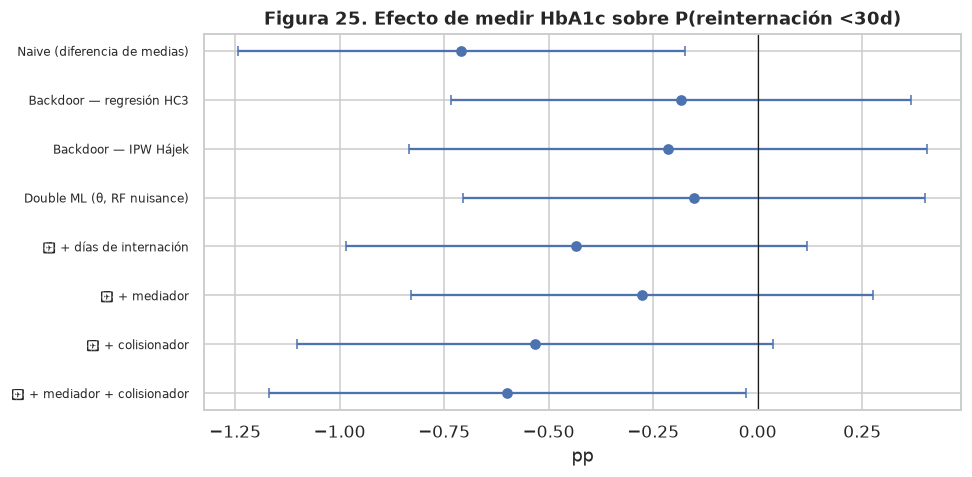

In [51]:
final_ref = pd.DataFrame([
    ("Naive (diferencia de medias)", naive["efecto_pp"], naive["ci_low_pp"], naive["ci_high_pp"]),
    ("Backdoor — regresión HC3", backdoor["efecto_pp"], backdoor["ci_low_pp"], backdoor["ci_high_pp"]),
    ("Backdoor — IPW Hájek", ipw, ipw_ci[0], ipw_ci[1]),
    ("Double ML (θ, RF nuisance)", dml_ref["ate_pp"], dml_ref["ci_low_pp"], dml_ref["ci_high_pp"]),
    ("❌ + días de internación", *trampas.loc["❌ Z + días de internación", ["efecto_pp", "ci_low_pp", "ci_high_pp"]]),
    ("❌ + mediador", *trampas.loc["❌ Z + mediador (cambio_med)", ["efecto_pp", "ci_low_pp", "ci_high_pp"]]),
    ("❌ + colisionador", *trampas.loc["❌ Z + colisionador (nº análisis)", ["efecto_pp", "ci_low_pp", "ci_high_pp"]]),
    ("❌ + mediador + colisionador", *trampas.loc["❌ Z + mediador + colisionador", ["efecto_pp", "ci_low_pp", "ci_high_pp"]]),
], columns=["Estimador", "ATE (pp)", "IC95% inf", "IC95% sup"]).set_index("Estimador")
display(final_ref)
fig, ax = plt.subplots(figsize=(9, 4.5))
yy = np.arange(len(final_ref))[::-1]
ax.errorbar(final_ref["ATE (pp)"], yy, xerr=[final_ref["ATE (pp)"] - final_ref["IC95% inf"],
                                             final_ref["IC95% sup"] - final_ref["ATE (pp)"]], fmt="o", capsize=3)
ax.axvline(0, color="k", lw=.8)
ax.set_yticks(yy, final_ref.index, fontsize=8)
ax.set(title=f"Figura {next(FIG)}. Efecto de medir HbA1c sobre P(reinternación <30d)", xlabel="pp")
plt.tight_layout()
plt.show()

In [52]:
# [DoWhy+EconML] contraste con las librerías
final = pd.concat([final_ref, pd.DataFrame([
    ("DoWhy — backdoor.linear_regression", 100 * est_lr.value, np.nan, np.nan),
    ("DoWhy — backdoor.propensity_score_weighting", 100 * est_ipw.value, np.nan, np.nan),
    ("EconML — LinearDML (ATE)", 100 * ate_l, 100 * lo_l, 100 * hi_l),
    ("EconML — CausalForestDML (ATE)", 100 * ate_cf, 100 * lo_cf, 100 * hi_cf),
], columns=["Estimador", "ATE (pp)", "IC95% inf", "IC95% sup"]).set_index("Estimador")])
display(final)

,ATE (pp),IC95% inf,IC95% sup
Estimador,,,
Naive (diferencia de medias),-0.7087,-1.2431,-0.1743
Backdoor — regresión HC3,-0.1837,-0.7337,0.3662
Backdoor — IPW Hájek,-0.2151,-0.8350,0.4049
"Double ML (θ, RF nuisance)",-0.1522,-0.7054,0.4009
❌ + días de internación,-0.4337,-0.9857,0.1183
❌ + mediador,-0.2762,-0.8282,0.2757
❌ + colisionador,-0.5321,-1.1012,0.0369
❌ + mediador + colisionador,-0.5986,-1.1688,-0.0283
DoWhy — backdoor.linear_regression,-0.1837,NaN,NaN


Todos los estimadores que respetan el criterio backdoor coinciden en un efecto promedio chico, entre −0,15 y −0,26 pp, con intervalos que incluyen el 0: regresión −0,18 (DoWhy reproduce exactamente el mismo valor), IPW −0,22 (−0,23 en DoWhy, que estima el propensity sin cross-fitting), DML propio −0,15 y LinearDML de EconML −0,26. La diferencia entre los dos DML viene de los Random Forest de nuisance (hiperparámetros y azar distintos) y es mucho menor que el ancho de los intervalos (≈ 1,2 pp). El CausalForestDML da −0,21 pero con un intervalo enorme (−2,95; 2,52). Los que lo violan (naive, + días, + mediador/colisionador) exageran el beneficio. La sofisticación del estimador (DML, bosques causales) **no cambia la conclusión**: lo que la define es **qué** se ajusta, y eso lo decide el DAG.

# 12. Ensayo crítico: el choque entre capacidad predictiva y palanca causal

**¿Puede la dirección considerar la variable más importante del Random Forest como palanca?** La variable más importante (por permutación) es **`log_number_inpatient`**, las internaciones del último año. **No es una palanca:** es un hecho pasado, no se puede intervenir. Predice bien porque es un **marcador** de un estado latente (fragilidad, mala adherencia, enfermedad avanzada) que causa tanto las internaciones previas como la futura. Si el hospital "redujera" artificialmente ese número (por ejemplo, reclasificando internaciones como observaciones), el riesgo real no cambiaría: estaría manipulando el termómetro, no la fiebre.

**¿Cuándo una variable muy predictiva no tiene poder causal, o tiene signo opuesto?**

1. **Confusión (causa común):** $X \leftarrow U \rightarrow Y$. Las internaciones previas y la reinternación comparten la gravedad latente. Alta importancia, efecto causal ~0.
2. **Causalidad inversa / indicación:** $Y$ o su riesgo causa $X$. `cambio_med` y `diabetesMed` tienen OR > 1 en la logística: los médicos ajustan el tratamiento **porque** el paciente está peor. Un ejecutivo ingenuo concluiría "cambiar la medicación aumenta la reinternación", cuando el efecto causal del ajuste podría ser protector (en la simulación de §11.3, $M$ reduce el riesgo).
3. **Selección / colisionadores:** el número de análisis predice la reinternación (MDI alto), pero condicionar en él induce sesgo; no es una palanca (pedir más análisis no reduce reinternaciones).
4. **Inversión de signo (Simpson):** nuestro propio tratamiento lo ilustra: la asociación cruda dice "−0,71 pp, significativo"; el efecto causal ajustado es ≈ 0. Y en el subgrupo circulatorio, la asociación negativa global esconde un efecto **positivo** (perjudicial).
5. **Importancia ≠ efecto de intervenir:** `hba1c_medida` tiene importancia predictiva **≈ 0** en el Random Forest, y sin embargo es la **única** variable del modelo que el hospital puede mover, y tiene un efecto causal **heterogéneo** relevante en un subgrupo. La importancia mide cuánto ayuda una variable a **predecir dada la política actual**, no cuánto cambia $Y$ si **cambiamos la política**.

**Moraleja:** el modelo predictivo responde **a quién mirar** (triage); el modelo causal responde **qué hacer** (política). Se necesitan los dos, y confundirlos lleva a optimizar correlaciones espurias.

# 13. De la inferencia a la decisión

Regla: aplicar el protocolo (test + revisión del tratamiento + seguimiento) al paciente $i$ si $\widehat{CATE}(x_i) < -\delta$, con $\delta$ = reducción mínima que justifica el costo.

,Política,% pacientes,Reinternaciones evitadas,Evitadas cada 100 tests,Costo protocolo (USD),Ahorro bruto (USD),Retorno neto (USD)
0,Política actual (observada),18.3579,17.7677,0.1383,"1,284,500.0000","266,515.4864","-1,017,984.5136"
1,Medir a todos,100.0000,168.2094,0.2404,"6,997,000.0000","2,523,140.8030","-4,473,859.1970"
2,Focalizada (CATE < −1 pp),11.0333,200.9140,2.6025,"772,000.0000","3,013,710.2494","2,241,710.2494"
3,Focalizada conservadora (IC sup. < 0),8.1449,166.0318,2.9134,"569,900.0000","2,490,477.3524","1,920,577.3524"


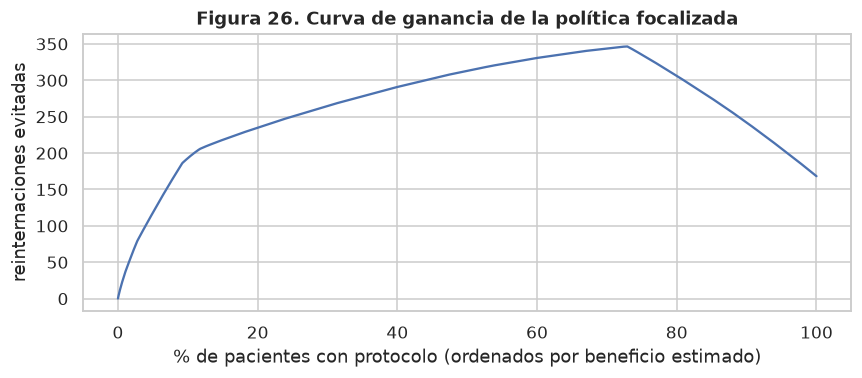

In [53]:
DELTA = 0.01
COSTO_REINTERNACION = 15_000  # USD, valor ilustrativo (supuesto editable)
COSTO_PROTOCOLO = 100  # USD por paciente: test + revisión médica (supuesto editable)
tau_all, lo_all, hi_all = C.cate_predict(dml_ref["cate_coef"], dml_ref["cate_cov"], d_c[X_cate].to_numpy(float))
pol = C.policy_table(tau_all, hi_all, d_c.hba1c_medida.to_numpy(), delta=DELTA)
pol["Costo protocolo (USD)"] = pol["% pacientes"] / 100 * len(d_c) * COSTO_PROTOCOLO
pol["Ahorro bruto (USD)"] = pol["Reinternaciones evitadas"] * COSTO_REINTERNACION
pol["Retorno neto (USD)"] = pol["Ahorro bruto (USD)"] - pol["Costo protocolo (USD)"]
display(pol)
orden_b = np.argsort(tau_all)
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(np.arange(1, len(tau_all) + 1) / len(tau_all) * 100, -np.cumsum(tau_all[orden_b]))
ax.set(title=f"Figura {next(FIG)}. Curva de ganancia de la política focalizada",
       xlabel="% de pacientes con protocolo (ordenados por beneficio estimado)", ylabel="reinternaciones evitadas")
plt.tight_layout()
plt.show()

**Recomendación operativa (cuantificada):**

1. **Focalizar** el protocolo de HbA1c + revisión de tratamiento + seguimiento en pacientes **con ≥1 internación en el último año y diagnóstico principal no circulatorio**. La política focalizada (CATE < −1 pp) cubre al **11%** de los pacientes y evita ≈ **2,6 reinternaciones cada 100 protocolos**, frente a 0,24 si se mide a todos (≈ 11 veces más eficiente). Con los costos supuestos (USD 100 por protocolo, USD 15.000 por reinternación), es la única política con **retorno neto positivo** (≈ USD 2,2 M sobre esta cohorte), mientras que medir a todos tendría retorno negativo (−4,5 M).
2. **No** usar estos números para **dejar** de medir HbA1c en nadie: el test es barato y la guía clínica lo recomienda por razones que exceden la reinternación.
3. **Validar con un experimento:** como el efecto promedio no es significativo y el E-value es bajo, la recomendación es correr un **ensayo aleatorizado por conglomerados** (por servicio o por semana) en el subgrupo focalizado. Con la tasa basal de ~15% en ese grupo y un efecto de −2 pp, se necesitan ≈ **5.000 pacientes por brazo** para 80% de potencia (cálculo con `tpi.stats.power_two_proportions`).
4. **Triage predictivo** en paralelo: usar el Random Forest para priorizar el seguimiento post-alta del decil de mayor riesgo (tasa real 16,9%, 1,9× la media).

**Limitaciones:** datos 1999–2008 de EE.UU. (validez externa para Argentina 2026 limitada); confusión no observada plausible (gravedad clínica, adherencia); HbA1c medida es un **proxy** de "atención a la diabetes" (el efecto podría venir de las acciones asociadas, no del test en sí); los costos son ilustrativos.

# 14. Exportación de artefactos para la app

La app (`app/app.py`) no reentrena nada: consume estos artefactos. El modelo de CATE exportado es la réplica auditable del LinearDML (§11.4), con coeficientes y matriz de covarianza HC3 para calcular intervalos para cualquier perfil.

In [54]:
from tpi.artifacts import export_all

refs_export = semaforo
try:  # si DoWhy corrió, se agrega su p-valor al semáforo
    for s_, (_, r_) in zip(refs_export, ref_dowhy.iterrows()):
        s_["p_valor_dowhy"] = float(r_["p-valor"]) if pd.notna(r_["p-valor"]) else None
        s_["nuevo_efecto_dowhy_pp"] = float(r_["Nuevo efecto (pp)"])
except NameError:
    pass
export_all(
    df=d_c, pca_pipe=pca_pipe, pred_pipe=best_rf,
    pred_metrics={k: float(v) for k, v in resultados["Random Forest"].items()},
    cate={"X_cols": X_cate, "coef": dml_ref["cate_coef"], "cov": dml_ref["cate_cov"], "ate_pp": dml_ref["ate_pp"],
          "ci_low_pp": dml_ref["ci_low_pp"], "ci_high_pp": dml_ref["ci_high_pp"]},
    ate_table=final if "final" in globals() else final_ref, refutations=refs_export,
    dag_edges=[list(e) for e in G.edges()], fuente_causal="DML con cross-fitting (réplica de EconML LinearDML)")
print("Artefactos exportados en app/artifacts/")

Artefactos exportados en app/artifacts/


# 15. Conclusiones

1. **Datos:** la auditoría encontró centinelas ocultos (≈ 10% de los tipos y ≈ 7% de los orígenes de admisión), pacientes repetidos que inflaban la tasa de reinternación en 2 pp y altas por fallecimiento con resultado indefinido. Los faltantes son MAR (rechazo formal de MCAR) y se modelan con categoría explícita.
2. **Inferencia clásica:** la asociación cruda HbA1c–reinternación es significativa pero de tamaño despreciable ($h$ = 0,025); el diseño sólo detecta efectos ≥ 0,8 pp con potencia 80%. La polifarmacia difiere por edad (Welch, Games-Howell) con $\eta^2$ = 1,6%.
3. **Regresión:** la estadía se explica en ~31% por la intensidad del tratamiento; los supuestos de homocedasticidad y normalidad se violan y se corrigen con log + HC3; no hay puntos influyentes que alteren conclusiones.
4. **Predicción:** AUC ≈ 0,62 con RF ≈ logística; NB Gaussiano está mal calibrado (corregible); el árbol podado da una regla simple (internaciones previas). Útil para **ordenar** riesgo (lift 1,9 en el decil superior), no para clasificar. MDI es engañosa: un ruido puro queda 1º.
5. **Causalidad:** el efecto promedio de medir HbA1c es ≈ −0,2 pp, no distinguible de 0, una vez ajustado correctamente; el 74% del beneficio aparente era autoselección. Hay heterogeneidad: beneficio en pacientes con internaciones previas no circulatorios. Ajustar por variables post-tratamiento (días, cambio de medicación, nº de análisis) fabrica efectos.
6. **Decisión:** política focalizada + ensayo aleatorizado para confirmar.

## Referencias

* Strack, B., DeShazo, J. P., Gennings, C., Olmo, J. L., Ventura, S., Cios, K. J., & Clore, J. N. (2014). Impact of HbA1c measurement on hospital readmission rates: analysis of 70,000 clinical database patient records. *BioMed Research International*, 2014, 781670.
* UCI Machine Learning Repository. *Diabetes 130-US Hospitals for Years 1999–2008* (id 296). https://archive.ics.uci.edu/dataset/296
* Pearl, J. (2009). *Causality* (2ª ed.). Cambridge University Press.
* Chernozhukov, V., et al. (2018). Double/debiased machine learning for treatment and structural parameters. *The Econometrics Journal*, 21(1), C1–C68.
* VanderWeele, T. J., & Ding, P. (2017). Sensitivity analysis in observational research: introducing the E-value. *Annals of Internal Medicine*, 167(4), 268–274.
* MacKinnon, J. G., & White, H. (1985). Some heteroskedasticity-consistent covariance matrix estimators with improved finite sample properties. *Journal of Econometrics*, 29(3), 305–325.
* Welch, B. L. (1951). On the comparison of several mean values: an alternative approach. *Biometrika*, 38(3/4), 330–336.
* Games, P. A., & Howell, J. F. (1976). Pairwise multiple comparison procedures with unequal n's and/or variances. *Journal of Educational Statistics*, 1(2), 113–125.
* Hanley, J. A., & McNeil, B. J. (1982). The meaning and use of the area under a ROC curve. *Radiology*, 143(1), 29–36.
* Strobl, C., Boulesteix, A.-L., Zeileis, A., & Hothorn, T. (2007). Bias in random forest variable importance measures. *BMC Bioinformatics*, 8, 25.
* Sharma, A., & Kiciman, E. (2020). DoWhy: An end-to-end library for causal inference. arXiv:2011.04216.
* Battocchi, K., et al. (2019). EconML: A Python package for ML-based heterogeneous treatment effects estimation. https://github.com/py-why/EconML

## Declaración de uso de IA generativa

Ver la **Entrada 5** de `BITACORA.md`: herramienta utilizada, prompts de diseño, errores detectados en las respuestas de la IA y pruebas determinísticas (`tests/`) creadas para refutarlos.